# An Explainable CNN-based Framework for Brain Tumor Classification and Localization using MRI Images
**Complete project notebook (M.Tech dissertation) — one file, run top to bottom in a single kernel.**

Dataset: Figshare brain tumor MRI (3,064 `.mat` slices, 233 patients; meningioma / glioma / pituitary).

| # | Pipeline step | Section in this notebook |
|---|---|---|
| 1 | MRI | Section 1 – environment, project folders, dataset check; Section 2 – `.mat` inspection |
| 2 | Pre-processing | Section 2 – `.mat` → PNG + masks + metadata; Section 3 – patient-wise split |
| 3 | CNN / Transfer learning | Sections 4–5 – EfficientNetB0, ResNet50 (two-stage fine-tuning) |
| 4 | Tumor classification | Sections 4–5 (test evaluation), Section 8 (multi-task model) |
| 5 | XAI | Section 6 – CAM engine on logits (Grad-CAM, Grad-CAM++, HiResCAM, LayerCAM) |
| 6 | Tumor heat-map | Section 6, Section 11 (cached final heat-maps) |
| 7 | Localization | Sections 7–9, Section 12 (heat-map → region → bounding box) |
| 8 | XAI region vs ground truth | Sections 10, 13 |
| 9 | Quantitative analysis | Sections 9–10, 14 |
| 10 | Robustness / Generalization | Sections 15–16 |
| 11 | Results | Section 17 |

**How to run**
1. Use one conda environment (your `brainxai`: Python 3.11, TensorFlow 2.21). Install TensorFlow *once* in a terminal (`pip install tensorflow`), not inside the notebook.
2. Check the two paths used throughout: `PROJECT_DIR = ~/Documents/BrainTumor_XAI_Restart` (outputs) and `SOURCE_DIR = ~/Documents/BrainTumor_XAI/data/processed/mat_files` (the 3,064 original `.mat` files).
3. Training cells (Sections 4, 5, 8) take hours on CPU. If the `.keras` model files already exist in `PROJECT_DIR/models`, you can skip those cells and the later sections load the saved models.
4. Rule used everywhere: every setting is chosen on **validation**; the **test** set is only used for reporting.

## 1. Environment, project folders and dataset check (Phase 1)

In [1]:
# Phase 1.1 — Cell 1: Check Python environment

import sys
from pathlib import Path

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Project setup started.")

Python version: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
Python executable: C:\Users\lokes\.conda\envs\brainxai\python.exe
Project setup started.


In [2]:
# Phase 1.1 — Cell 2: Set project paths

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"

print("New project directory:", PROJECT_DIR)
print("Directory already exists:", PROJECT_DIR.exists())

New project directory: C:\Users\lokes\Documents\BrainTumor_XAI_Restart
Directory already exists: True


In [3]:
# Phase 1.1 — Cell 3: Create project folders

FOLDERS = [
    "data/original_mat",
    "data/processed/images",
    "data/processed/masks",
    "data/metadata",
    "notebooks",
    "models/efficientnetb0",
    "models/resnet50",
    "results/classification",
    "results/localization",
    "results/robustness",
    "results/figures",
    "logs"
]

for folder in FOLDERS:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project folders created or already available.")
print("Total folders checked:", len(FOLDERS))

Project folders created or already available.
Total folders checked: 12


In [4]:
# Phase 1.1 — Cell 4: Check required libraries

import importlib

REQUIRED_LIBRARIES = [
    "numpy",
    "pandas",
    "PIL",
    "h5py",
    "sklearn",
    "matplotlib",
    "tensorflow"
]

for library in REQUIRED_LIBRARIES:
    try:
        module = importlib.import_module(library)
        version = getattr(module, "__version__", "Version not reported")
        print(f"OK      {library}: {version}")
    except Exception as error:
        print(f"MISSING {library}: {error}")

OK      numpy: 2.4.6
OK      pandas: 3.1.0
OK      PIL: 12.3.0
OK      h5py: 3.14.0
OK      sklearn: 1.9.1
OK      matplotlib: 3.11.2
OK      tensorflow: 2.21.0


In [5]:
# Phase 1.1 — Cell 6: Verify TensorFlow

import tensorflow as tf
import sys

print("TensorFlow version:", tf.__version__)
print("Python executable:", sys.executable)
print("TensorFlow imported successfully.")

TensorFlow version: 2.21.0
Python executable: C:\Users\lokes\.conda\envs\brainxai\python.exe
TensorFlow imported successfully.


In [6]:
# Phase 1.1 — Cell 7: Check TensorFlow and GPU

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU available:", True)
    for gpu in gpus:
        print(gpu)
else:
    print("GPU available:", False)
    print("We will configure training for CPU if needed.")

TensorFlow version: 2.21.0
GPU available: False
We will configure training for CPU if needed.


In [7]:
# Phase 1.1 — Cell 8: Locate original MAT files

from pathlib import Path

POSSIBLE_DATASET_DIRS = [
    Path.home() / "Documents" / "BrainTumor_XAI" / "data" / "processed" / "mat_files",
    Path.home() / "Documents" / "BrainTumor_XAI" / "data" / "original_mat"
]

for folder in POSSIBLE_DATASET_DIRS:
    if folder.is_dir():
        mat_files = list(folder.glob("*.mat"))
        print("\nDataset folder:", folder)
        print("MAT files found:", len(mat_files))
        print("Sample filenames:", [f.name for f in mat_files[:5]])
    else:
        print("\nFolder not found:", folder)


Dataset folder: C:\Users\lokes\Documents\BrainTumor_XAI\data\processed\mat_files
MAT files found: 3064
Sample filenames: ['1.mat', '10.mat', '100.mat', '1000.mat', '1001.mat']

Folder not found: C:\Users\lokes\Documents\BrainTumor_XAI\data\original_mat


In [8]:
# Phase 1.1 — Cell 9: Validate original MAT files

from pathlib import Path

SOURCE_DIR = (
    Path.home()
    / "Documents"
    / "BrainTumor_XAI"
    / "data"
    / "processed"
    / "mat_files"
)

mat_files = sorted(
    SOURCE_DIR.glob("*.mat"),
    key=lambda path: int(path.stem)
    if path.stem.isdigit() else path.stem
)

print("Source directory exists:", SOURCE_DIR.is_dir())
print("Total MAT files:", len(mat_files))
print("First five files:", [f.name for f in mat_files[:5]])
print("All files use .mat extension:", all(f.suffix == ".mat" for f in mat_files))

assert SOURCE_DIR.is_dir(), "Source directory does not exist."
assert len(mat_files) == 3064, (
    f"Expected 3064 files, but found {len(mat_files)}. "
    "Check the source dataset before continuing."
)

print("\nPhase 1 dataset checks passed.")

Source directory exists: True
Total MAT files: 3064
First five files: ['1.mat', '2.mat', '3.mat', '4.mat', '5.mat']
All files use .mat extension: True

Phase 1 dataset checks passed.


## 2. MAT inspection → PNG/mask conversion → validation (Phase 2)
Each `.mat` holds `cjdata` with image, tumorMask, label (1 meningioma, 2 glioma, 3 pituitary), PID and tumorBorder. Images are min–max scaled to 8-bit PNG; masks are stored as exact 0/255.

In [9]:
# Phase 2 — Cell 1: Inspect one original MAT file

from pathlib import Path
import h5py

# Define the original dataset location
SOURCE_DIR = (
    Path.home()
    / "Documents"
    / "BrainTumor_XAI"
    / "data"
    / "processed"
    / "mat_files"
)

sample_file = SOURCE_DIR / "1.mat"

# Confirm that the file exists
assert sample_file.exists(), f"File not found: {sample_file}"

print("Inspecting:", sample_file)
print("\nMAT file structure:")

# Inspect stored variables without modifying the file
with h5py.File(sample_file, "r") as mat_file:

    def inspect_item(name, item):
        if isinstance(item, h5py.Dataset):
            print(
                f"{name} | Shape: {item.shape} | "
                f"Data type: {item.dtype}"
            )
        elif isinstance(item, h5py.Group):
            print(f"{name} | Group")

    mat_file.visititems(inspect_item)

Inspecting: C:\Users\lokes\Documents\BrainTumor_XAI\data\processed\mat_files\1.mat

MAT file structure:
cjdata | Group
cjdata/PID | Shape: (6, 1) | Data type: uint16
cjdata/image | Shape: (512, 512) | Data type: int16
cjdata/label | Shape: (1, 1) | Data type: float64
cjdata/tumorBorder | Shape: (1, 38) | Data type: float64
cjdata/tumorMask | Shape: (512, 512) | Data type: uint8


In [10]:
# Phase 2 — Cell 2: Read and validate one sample

import h5py
import numpy as np

sample_file = SOURCE_DIR / "1.mat"

with h5py.File(sample_file, "r") as mat_file:
    data = mat_file["cjdata"]

    image = np.array(data["image"])
    mask = np.array(data["tumorMask"])
    label = np.array(data["label"]).squeeze()
    patient_id = np.array(data["PID"]).squeeze()

print("Image shape:", image.shape)
print("Image data type:", image.dtype)
print("Image intensity range:", image.min(), "to", image.max())

print("\nMask shape:", mask.shape)
print("Mask data type:", mask.dtype)
print("Mask unique values:", np.unique(mask))
print("Tumor pixels:", np.count_nonzero(mask))

print("\nClass label:", label)
print("Patient ID:", patient_id)

assert image.shape == mask.shape, "Image and mask dimensions differ."
assert image.ndim == 2, "Expected a 2D MRI image."
assert np.isfinite(image).all(), "Image contains invalid values."
assert np.isfinite(mask).all(), "Mask contains invalid values."

print("\nSample validation passed.")

Image shape: (512, 512)
Image data type: int16
Image intensity range: 0 to 3366

Mask shape: (512, 512)
Mask data type: uint8
Mask unique values: [0 1]
Tumor pixels: 4569

Class label: 1.0
Patient ID: [49 48 48 51 54 48]

Sample validation passed.


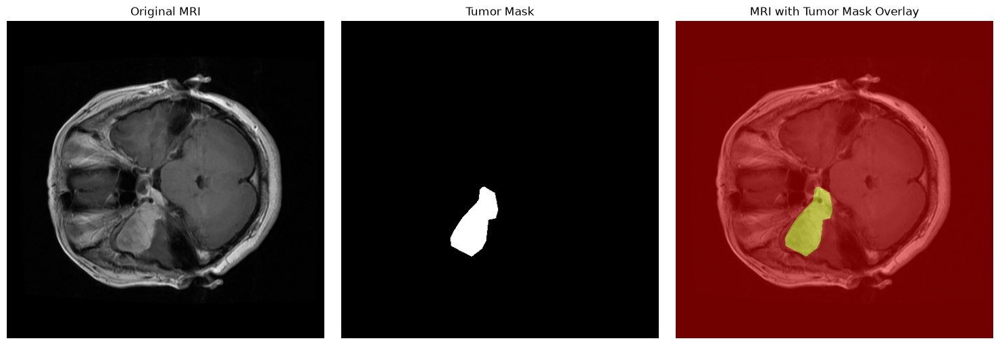

MRI shape: (512, 512)
Mask shape: (512, 512)
Tumor pixels: 4569


In [11]:
# Phase 2 — Cell 3: Visualize MRI and tumor-mask alignment

from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

SOURCE_DIR = (
    Path.home()
    / "Documents"
    / "BrainTumor_XAI"
    / "data"
    / "processed"
    / "mat_files"
)

sample_file = SOURCE_DIR / "1.mat"

with h5py.File(sample_file, "r") as mat_file:
    data = mat_file["cjdata"]
    image = np.array(data["image"])
    mask = np.array(data["tumorMask"])

# Normalize the MRI for display only; original values remain unchanged.
image_display = image.astype(np.float32)
image_display = (
    (image_display - image_display.min())
    / (image_display.max() - image_display.min() + 1e-8)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_display, cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Tumor Mask")

axes[2].imshow(image_display, cmap="gray")
axes[2].imshow(mask, cmap="autumn", alpha=0.45)
axes[2].set_title("MRI with Tumor Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("MRI shape:", image.shape)
print("Mask shape:", mask.shape)
print("Tumor pixels:", int(np.count_nonzero(mask)))

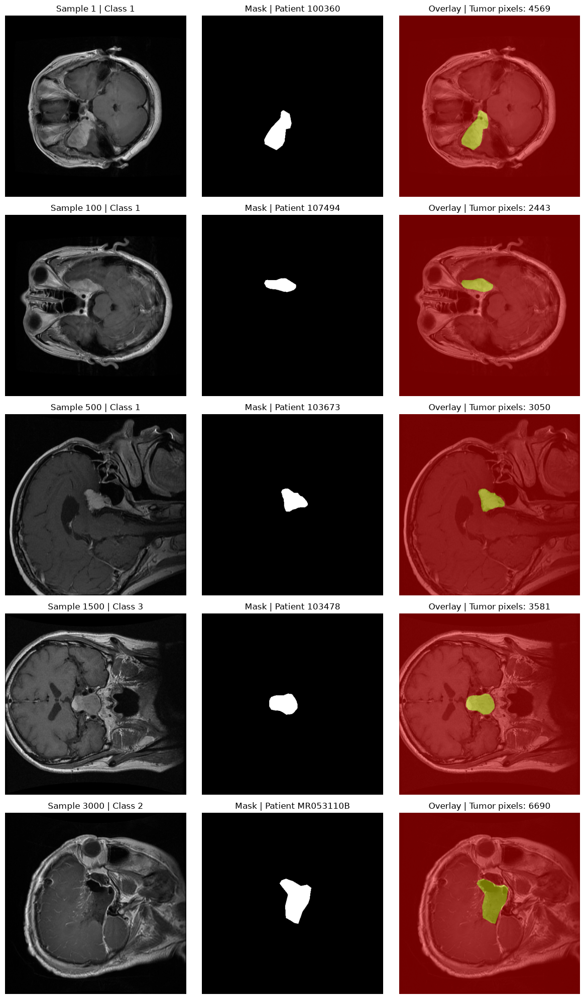

In [12]:
# Phase 2 — Cell 4: Multi-sample MRI and mask alignment check

from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

SOURCE_DIR = (
    Path.home()
    / "Documents"
    / "BrainTumor_XAI"
    / "data"
    / "processed"
    / "mat_files"
)

sample_ids = [1, 100, 500, 1500, 3000]

fig, axes = plt.subplots(len(sample_ids), 3, figsize=(12, 4 * len(sample_ids)))

for row, sample_id in enumerate(sample_ids):
    file_path = SOURCE_DIR / f"{sample_id}.mat"

    with h5py.File(file_path, "r") as mat_file:
        data = mat_file["cjdata"]
        image = np.array(data["image"])
        mask = np.array(data["tumorMask"])
        label = int(np.array(data["label"]).squeeze())
        pid_codes = np.array(data["PID"]).reshape(-1)

    # Decode MATLAB character codes into a patient ID.
    patient_id = "".join(
        chr(int(code)) for code in pid_codes if int(code) != 0
    )

    image_display = image.astype(np.float32)
    image_display = (
        (image_display - image_display.min())
        / (image_display.max() - image_display.min() + 1e-8)
    )

    axes[row, 0].imshow(image_display, cmap="gray")
    axes[row, 0].set_title(f"Sample {sample_id} | Class {label}")

    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"Mask | Patient {patient_id}")

    axes[row, 2].imshow(image_display, cmap="gray")
    axes[row, 2].imshow(mask, cmap="autumn", alpha=0.45)
    axes[row, 2].set_title(
        f"Overlay | Tumor pixels: {np.count_nonzero(mask)}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Phase 2 — Cell 5: Convert MATLAB files to PNG and create metadata

from pathlib import Path
import h5py
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SOURCE_DIR = (
    Path.home()
    / "Documents"
    / "BrainTumor_XAI"
    / "data"
    / "processed"
    / "mat_files"
)

IMAGE_DIR = PROJECT_DIR / "data" / "processed" / "images"
MASK_DIR = PROJECT_DIR / "data" / "processed" / "masks"
METADATA_DIR = PROJECT_DIR / "data" / "metadata"

for folder in [IMAGE_DIR, MASK_DIR, METADATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

mat_files = sorted(
    SOURCE_DIR.glob("*.mat"),
    key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem
)

assert len(mat_files) == 3064, (
    f"Expected 3064 MAT files, found {len(mat_files)}. "
    "Check SOURCE_DIR before proceeding."
)

# Standard Figshare label mapping; verify class counts afterward.
CLASS_MAP = {
    1: "meningioma",
    2: "glioma",
    3: "pituitary"
}

records = []
errors = []

for mat_path in tqdm(mat_files, desc="Converting MAT files"):
    try:
        with h5py.File(mat_path, "r") as mat_file:
            data = mat_file["cjdata"]

            image = np.array(data["image"])
            mask = np.array(data["tumorMask"])
            label = int(np.array(data["label"]).squeeze())
            pid_codes = np.array(data["PID"]).reshape(-1)

        patient_id = "".join(
            chr(int(code)) for code in pid_codes if int(code) != 0
        )

        if image.ndim != 2 or mask.ndim != 2:
            raise ValueError("Image and mask must both be 2D.")

        if image.shape != mask.shape:
            raise ValueError("Image and mask dimensions differ.")

        if not np.isfinite(image).all():
            raise ValueError("Image contains non-finite values.")

        if not np.isin(np.unique(mask), [0, 1]).all():
            raise ValueError("Mask is not binary.")

        if label not in CLASS_MAP:
            raise ValueError(f"Unexpected class label: {label}")

        # Normalize image intensities to 8-bit for PNG storage.
        image_float = image.astype(np.float32)
        image_min = float(image_float.min())
        image_max = float(image_float.max())

        if image_max > image_min:
            image_uint8 = np.round(
                (image_float - image_min)
                / (image_max - image_min) * 255
            ).astype(np.uint8)
        else:
            image_uint8 = np.zeros(image.shape, dtype=np.uint8)

        # Preserve the mask as exact binary values: 0 and 255.
        mask_uint8 = (mask > 0).astype(np.uint8) * 255

        image_name = f"{mat_path.stem}.png"
        mask_name = f"{mat_path.stem}_mask.png"

        Image.fromarray(image_uint8).save(IMAGE_DIR / image_name)
        Image.fromarray(mask_uint8).save(MASK_DIR / mask_name)

        records.append({
            "sample_id": mat_path.stem,
            "source_mat": str(mat_path),
            "patient_id": patient_id,
            "label": label,
            "class_name": CLASS_MAP[label],
            "image_path": str(IMAGE_DIR / image_name),
            "mask_path": str(MASK_DIR / mask_name),
            "original_height": image.shape[0],
            "original_width": image.shape[1],
            "tumor_pixels": int(np.count_nonzero(mask))
        })

    except Exception as exc:
        errors.append({
            "sample_id": mat_path.stem,
            "error": str(exc)
        })

metadata = pd.DataFrame(records)
metadata_path = METADATA_DIR / "dataset_metadata.csv"
metadata.to_csv(metadata_path, index=False)

print("\nCONVERSION SUMMARY")
print("MAT files found:", len(mat_files))
print("Successfully converted:", len(records))
print("Errors:", len(errors))
print("Unique patients:", metadata["patient_id"].nunique())
print("\nClass counts:")
print(metadata["class_name"].value_counts())
print("\nMetadata saved to:", metadata_path)

if errors:
    error_path = METADATA_DIR / "conversion_errors.csv"
    pd.DataFrame(errors).to_csv(error_path, index=False)
    print("Error details saved to:", error_path)

assert len(records) == 3064, (
    "Conversion incomplete. Review conversion_errors.csv before continuing."
)

print("\nPhase 2 conversion completed successfully.")

Converting MAT files:   0%|          | 0/3064 [00:00<?, ?it/s]


CONVERSION SUMMARY
MAT files found: 3064
Successfully converted: 3064
Errors: 0
Unique patients: 233

Class counts:
class_name
glioma        1426
pituitary      930
meningioma     708
Name: count, dtype: int64

Metadata saved to: C:\Users\lokes\Documents\BrainTumor_XAI_Restart\data\metadata\dataset_metadata.csv

Phase 2 conversion completed successfully.


In [14]:
# Phase 2 — Cell 6: Full PNG and metadata validation

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
IMAGE_DIR = PROJECT_DIR / "data" / "processed" / "images"
MASK_DIR = PROJECT_DIR / "data" / "processed" / "masks"
METADATA_PATH = (
    PROJECT_DIR / "data" / "metadata" / "dataset_metadata.csv"
)

metadata = pd.read_csv(METADATA_PATH)

problems = []
total_tumor_pixels = 0

for row in metadata.itertuples(index=False):
    image_path = Path(row.image_path)
    mask_path = Path(row.mask_path)

    if not image_path.exists() or not mask_path.exists():
        problems.append(f"Missing image or mask: {row.sample_id}")
        continue

    try:
        with Image.open(image_path) as img:
            image = np.array(img.convert("L"))

        with Image.open(mask_path) as msk:
            mask = np.array(msk.convert("L"))

        if image.shape != mask.shape:
            problems.append(f"Dimension mismatch: {row.sample_id}")
            continue

        if not set(np.unique(mask)).issubset({0, 255}):
            problems.append(f"Non-binary mask: {row.sample_id}")

        if not np.any(mask == 255):
            problems.append(f"Empty tumor mask: {row.sample_id}")

        total_tumor_pixels += int(np.count_nonzero(mask == 255))

    except Exception as exc:
        problems.append(f"Unreadable {row.sample_id}: {exc}")

print("Metadata records:", len(metadata))
print("Unique sample IDs:", metadata["sample_id"].nunique())
print("Unique patients:", metadata["patient_id"].nunique())
print("Image files:", len(list(IMAGE_DIR.glob("*.png"))))
print("Mask files:", len(list(MASK_DIR.glob("*.png"))))
print("Total tumor pixels across masks:", total_tumor_pixels)
print("Validation problems:", len(problems))

if problems:
    print("\nFirst 20 problems:")
    for problem in problems[:20]:
        print("-", problem)
else:
    print("\nAll converted image-mask pairs passed validation.")

assert len(metadata) == 3064, "Unexpected metadata record count."
assert metadata["sample_id"].nunique() == 3064, "Duplicate sample IDs."
assert len(list(IMAGE_DIR.glob("*.png"))) == 3064, "Image count mismatch."
assert len(list(MASK_DIR.glob("*.png"))) == 3064, "Mask count mismatch."
assert not problems, "Resolve validation problems before proceeding."

print("\nPhase 2 fully validated.")

Metadata records: 3064
Unique sample IDs: 3064
Unique patients: 233
Image files: 3064
Mask files: 3064
Total tumor pixels across masks: 13548142
Validation problems: 0

All converted image-mask pairs passed validation.

Phase 2 fully validated.


## 3. Patient-wise train / validation / test split (Phase 3)
Stratified on each patient's class, 70/15/15 of patients, no patient in more than one split.

In [15]:
# Phase 3 — Cell 1: Prepare patient-level metadata and split patients

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
METADATA_PATH = (
    PROJECT_DIR / "data" / "metadata" / "dataset_metadata.csv"
)
OUTPUT_PATH = (
    PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
)

metadata = pd.read_csv(METADATA_PATH, dtype={"patient_id": str})
metadata["patient_id"] = metadata["patient_id"].str.strip()
metadata["sample_id"] = metadata["sample_id"].astype(str)

assert metadata["patient_id"].notna().all(), "Missing patient IDs."
assert (metadata["patient_id"] != "").all(), "Empty patient IDs."
assert metadata["sample_id"].nunique() == len(metadata), "Duplicate samples."

# Summarize each patient's image and class composition.
patient_summary = (
    metadata.groupby("patient_id")
    .agg(
        image_count=("sample_id", "size"),
        class_count=("class_name", "nunique"),
        patient_class=("class_name", lambda x: x.mode().iloc[0])
    )
    .reset_index()
)

print("Total images:", len(metadata))
print("Unique patients:", len(patient_summary))
print("Patients with images from multiple classes:",
      int((patient_summary["class_count"] > 1).sum()))

print("\nPatient counts by dominant class:")
print(patient_summary["patient_class"].value_counts())

# Stratify on the dominant class only if every class has enough patients.
class_patient_counts = patient_summary["patient_class"].value_counts()
can_stratify = (
    len(class_patient_counts) > 1
    and class_patient_counts.min() >= 3
)

if can_stratify:
    train_patients, remaining_patients = train_test_split(
        patient_summary,
        test_size=0.30,
        random_state=42,
        stratify=patient_summary["patient_class"]
    )

    val_patients, test_patients = train_test_split(
        remaining_patients,
        test_size=0.50,
        random_state=42,
        stratify=remaining_patients["patient_class"]
    )
else:
    raise ValueError(
        "Patient-level stratification is not feasible with the current "
        "class counts. Inspect patient_summary before choosing another split."
    )

split_lookup = {}

for split_name, frame in [
    ("train", train_patients),
    ("validation", val_patients),
    ("test", test_patients)
]:
    for patient_id in frame["patient_id"]:
        split_lookup[patient_id] = split_name

metadata["split"] = metadata["patient_id"].map(split_lookup)

assert metadata["split"].notna().all(), "Some patients were not assigned."
assert metadata.groupby("patient_id")["split"].nunique().max() == 1, (
    "Patient leakage detected."
)

metadata.to_csv(OUTPUT_PATH, index=False)

print("\nPatient split counts:")
print(patient_summary.assign(
    split=patient_summary["patient_id"].map(split_lookup)
)["split"].value_counts())

print("\nImage split counts:")
print(metadata["split"].value_counts())

print("\nClass counts by split:")
print(pd.crosstab(metadata["split"], metadata["class_name"]))

print("\nSaved split metadata to:", OUTPUT_PATH)
print("\nPatient-wise split created successfully.")

Total images: 3064
Unique patients: 233
Patients with images from multiple classes: 0

Patient counts by dominant class:
patient_class
glioma        89
meningioma    82
pituitary     62
Name: count, dtype: int64

Patient split counts:
split
train         163
test           35
validation     35
Name: count, dtype: int64

Image split counts:
split
train         2084
validation     491
test           489
Name: count, dtype: int64

Class counts by split:
class_name  glioma  meningioma  pituitary
split                                    
test           224         116        149
train          990         443        651
validation     212         149        130

Saved split metadata to: C:\Users\lokes\Documents\BrainTumor_XAI_Restart\data\metadata\patient_split_metadata.csv

Patient-wise split created successfully.


In [16]:
# Phase 3 — Cell 2: Verify patient leakage and split integrity

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH = (
    PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
)

df = pd.read_csv(
    SPLIT_PATH,
    dtype={"patient_id": str, "sample_id": str}
)

# Check that every patient belongs to exactly one split.
patient_split_counts = df.groupby("patient_id")["split"].nunique()
leaked_patients = patient_split_counts[patient_split_counts > 1]

# Check that every sample has a valid split and its files exist.
valid_splits = {"train", "validation", "test"}
invalid_splits = sorted(set(df["split"].dropna()) - valid_splits)

missing_images = sum(
    not Path(path).is_file() for path in df["image_path"]
)
missing_masks = sum(
    not Path(path).is_file() for path in df["mask_path"]
)

print("Patient leakage:", len(leaked_patients))
print("Invalid or unexpected splits:", invalid_splits)
print("Missing image files:", missing_images)
print("Missing mask files:", missing_masks)
print("Duplicate sample IDs:", int(df["sample_id"].duplicated().sum()))

print("\nClass distribution by split:")
print(pd.crosstab(df["split"], df["class_name"]))

assert len(leaked_patients) == 0, "Patient leakage detected."
assert not invalid_splits, "Unexpected split labels detected."
assert missing_images == 0, "Missing images detected."
assert missing_masks == 0, "Missing masks detected."
assert not df["sample_id"].duplicated().any(), "Duplicate sample IDs detected."

print("\nPhase 3 integrity checks passed.")

Patient leakage: 0
Invalid or unexpected splits: []
Missing image files: 0
Missing mask files: 0
Duplicate sample IDs: 0

Class distribution by split:
class_name  glioma  meningioma  pituitary
split                                    
test           224         116        149
train          990         443        651
validation     212         149        130

Phase 3 integrity checks passed.


## 4. EfficientNetB0 — transfer learning (Phase 4)
Stage 1: frozen backbone, Adam 1e-3. Stage 2: fine-tune the last 30% of layers (BatchNorm frozen), Adam 1e-5. Early stopping on validation loss.

In [17]:
# Phase 4 — Cell 1: EfficientNetB0 environment and data setup

from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH = (
    PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
)
MODEL_DIR = PROJECT_DIR / "models" / "efficientnetb0"
RESULTS_DIR = PROJECT_DIR / "results" / "classification"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metadata = pd.read_csv(
    SPLIT_PATH,
    dtype={"patient_id": str, "sample_id": str}
)

CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
CLASS_TO_INDEX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

# Confirm metadata labels match the intended three classes.
assert set(metadata["class_name"].unique()) == set(CLASS_NAMES)
assert metadata["split"].notna().all()
assert metadata["image_path"].map(lambda p: Path(p).is_file()).all()

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Image size: 224 x 224")
print("Batch size: 8")
print("Classes:", CLASS_NAMES)

print("\nImage counts:")
print(metadata["split"].value_counts())

print("\nClass-to-index mapping:")
print(CLASS_TO_INDEX)

print("\nEfficientNetB0 environment checks passed.")

TensorFlow version: 2.21.0
Available GPUs: []
Image size: 224 x 224
Batch size: 8
Classes: ['glioma', 'meningioma', 'pituitary']

Image counts:
split
train         2084
validation     491
test           489
Name: count, dtype: int64

Class-to-index mapping:
{'glioma': 0, 'meningioma': 1, 'pituitary': 2}

EfficientNetB0 environment checks passed.


In [18]:
'''This cell loads the PNG images, resizes them to 224 × 224,
creates batches, and applies the correct class labels.
#It does not load the test images into the training process.'''
# Phase 4 — Cell 2: Create training and validation datasets

from pathlib import Path
import pandas as pd
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH = (
    PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
)

metadata = pd.read_csv(
    SPLIT_PATH,
    dtype={"patient_id": str, "sample_id": str}
)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8
CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_png(image_bytes, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)

    # EfficientNetB0 in Keras includes its own rescaling.
    # Keep input pixel values in the 0–255 range.
    return image, label

def make_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["class_name"].map(CLASS_TO_INDEX).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_df = metadata[metadata["split"] == "train"].copy()
val_df = metadata[metadata["split"] == "validation"].copy()

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

# Inspect one batch without starting model training.
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))
    print("Labels in batch:", labels.numpy())

Training images: 2084
Validation images: 491
Training batches: 261
Validation batches: 62
Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
Pixel range: 0.0 to 252.6990203857422
Labels in batch: [0 0 1 2 2 0 0 2]


In [19]:
# Phase 4 — Cell 3: Build the pretrained EfficientNetB0 classifier

from pathlib import Path
import tensorflow as tf
from tensorflow.keras import layers, models

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
MODEL_DIR = PROJECT_DIR / "models" / "efficientnetb0"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
NUM_CLASSES = 3

# Load ImageNet-pretrained backbone.
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMAGE_SIZE, 3)
)

# Freeze backbone for initial training.
base_model.trainable = False

inputs = layers.Input(shape=(*IMAGE_SIZE, 3), name="mri_input")

# EfficientNetB0 includes input rescaling internally.
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification_output"
)(x)

model = models.Model(inputs, outputs, name="efficientnetb0_classifier")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("\nTrainable parameters:",
      sum(tf.keras.backend.count_params(w) for w in model.trainable_weights))
print("Total parameters:",
      sum(tf.keras.backend.count_params(w) for w in model.weights))
print("\nEfficientNetB0 model built and compiled.")

Model: "efficientnetb0_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mri_input (InputLayer)               │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling               │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ classification_output (Dense)        │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Trainable parameters: 3843
Total parameters: 4053414

EfficientNetB0 model built and compiled.


In [20]:
# Phase 4 — Cell 4: Train EfficientNetB0 classification head

from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
MODEL_DIR = PROJECT_DIR / "models" / "efficientnetb0"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "efficientnetb0_stage1_best.keras"
LOG_PATH = MODEL_DIR / "efficientnetb0_stage1_history.csv"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(str(LOG_PATH))
]

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

print("\nStage 1 training completed.")
print("Best model path:", BEST_MODEL_PATH)
print("Training history:", LOG_PATH)
print("Epochs completed:", len(history_stage1.history["loss"]))
print("Best validation accuracy:",
      max(history_stage1.history["val_accuracy"]))
print("Best validation loss:",
      min(history_stage1.history["val_loss"]))

Epoch 1/15


C:\Users\lokes\.conda\envs\brainxai\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.7121 - loss: 0.6777
Epoch 1: val_loss improved from None to 0.44086, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\efficientnetb0\efficientnetb0_stage1_best.keras

Epoch 1: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\efficientnetb0\efficientnetb0_stage1_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 58s 177ms/step - accuracy: 0.7121 - loss: 0.6777 - val_accuracy: 0.8086 - val_loss: 0.4409
Epoch 2/15
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.8215 - loss: 0.4553
Epoch 2: val_loss did not improve from 0.44086
261/261 ━━━━━━━━━━━━━━━━━━━━ 43s 166ms/step - accuracy: 0.8215 - loss: 0.4553 - val_accuracy: 0.7637 - val_loss: 0.4844
Epoch 3/15
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.8508 - loss: 0.3953
Epoch 3: val_loss improved from 0.44086 to 0.33330, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\efficientnetb0\efficientnetb0_s

In [21]:
# Phase 4 — Cell 5: Fine-tune the later EfficientNetB0 layers

from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
MODEL_DIR = PROJECT_DIR / "models" / "efficientnetb0"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load the best Stage 1 model.
model = tf.keras.models.load_model(
    MODEL_DIR / "efficientnetb0_stage1_best.keras"
)

# Locate and selectively unfreeze the backbone.
base_model = model.get_layer("efficientnetb0")
base_model.trainable = True

# Keep early layers frozen; fine-tune the later layers only.
fine_tune_from = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    # Keep BatchNormalization layers frozen.
    layer.trainable = not isinstance(
        layer, tf.keras.layers.BatchNormalization
    )

# Compile again with a small learning rate.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Total backbone layers:", len(base_model.layers))
print("Fine-tuning starts at layer:", fine_tune_from)
print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))
print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w) for w in model.trainable_weights))

print("\nFine-tuning model compiled successfully.")

Total backbone layers: 238
Fine-tuning starts at layer: 166
Trainable backbone layers: 57
Trainable parameters: 3058463

Fine-tuning model compiled successfully.


In [22]:
# Phase 4 — Cell 6: Train the fine-tuned EfficientNetB0 model

from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
MODEL_DIR = PROJECT_DIR / "models" / "efficientnetb0"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "efficientnetb0_finetuned_best.keras"
FINAL_MODEL_PATH = MODEL_DIR / "efficientnetb0_finetuned_final.keras"
LOG_PATH = MODEL_DIR / "efficientnetb0_finetune_history.csv"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(str(LOG_PATH))
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

# Save the best restored model as the final fine-tuned checkpoint.
model.save(FINAL_MODEL_PATH)

print("\nFine-tuning completed.")
print("Epochs completed:", len(history_finetune.history["loss"]))
print("Best validation accuracy:",
      max(history_finetune.history["val_accuracy"]))
print("Best validation loss:",
      min(history_finetune.history["val_loss"]))
print("Best checkpoint:", BEST_MODEL_PATH)
print("Final checkpoint:", FINAL_MODEL_PATH)
print("Training history:", LOG_PATH)

Epoch 1/8
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.8925 - loss: 0.2646
Epoch 1: val_loss improved from None to 0.31599, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\efficientnetb0\efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\efficientnetb0\efficientnetb0_finetuned_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 74s 225ms/step - accuracy: 0.8925 - loss: 0.2646 - val_accuracy: 0.8656 - val_loss: 0.3160
Epoch 2/8
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9064 - loss: 0.2351
Epoch 2: val_loss improved from 0.31599 to 0.26775, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\efficientnetb0\efficientnetb0_finetuned_best.keras

Epoch 2: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\efficientnetb0\efficientnetb0_finetuned_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 57s 218ms/step - accuracy: 0.9064 - loss: 0.2351 -

In [23]:
# Phase 4 — Cell 7: EfficientNetB0 final test evaluation

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH = PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
MODEL_PATH = PROJECT_DIR / "models" / "efficientnetb0" / "efficientnetb0_finetuned_best.keras"
RESULTS_DIR = PROJECT_DIR / "results" / "classification"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8
CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

# Load the held-out test records
metadata = pd.read_csv(
    SPLIT_PATH,
    dtype={"patient_id": str, "sample_id": str}
)
test_df = metadata[metadata["split"] == "test"].copy()

def load_test_image(image_path, label):
    image = tf.io.decode_png(
        tf.io.read_file(image_path), channels=3
    )
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

test_paths = test_df["image_path"].astype(str).to_numpy()
test_labels = test_df["class_name"].map(CLASS_TO_INDEX).to_numpy()

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)
test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Load the best checkpoint selected using validation data
model = tf.keras.models.load_model(MODEL_PATH)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = test_labels

print("\n===== EfficientNetB0 Test Results =====")
print(f"Test images: {len(test_df)}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Accuracy (%): {test_accuracy * 100:.2f}")
print(f"Macro F1-score: {f1_score(y_true, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
print("Confusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))

# Save predictions and metrics for later comparison with ResNet50
predictions_df = test_df[["sample_id", "patient_id", "class_name"]].copy()
predictions_df["actual_index"] = y_true
predictions_df["predicted_index"] = y_pred
predictions_df["predicted_class"] = [CLASS_NAMES[i] for i in y_pred]
predictions_df["prediction_confidence"] = probabilities.max(axis=1)

predictions_df.to_csv(
    RESULTS_DIR / "efficientnetb0_test_predictions.csv",
    index=False
)

metrics_df = pd.DataFrame([{
    "model": "EfficientNetB0",
    "test_images": len(test_df),
    "test_loss": float(test_loss),
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_f1": float(f1_score(y_true, y_pred, average="macro"))
}])
metrics_df.to_csv(
    RESULTS_DIR / "efficientnetb0_test_metrics.csv",
    index=False
)

print("\nSaved test predictions and metrics to:")
print(RESULTS_DIR)

62/62 ━━━━━━━━━━━━━━━━━━━━ 13s 124ms/step - accuracy: 0.8466 - loss: 0.3639
62/62 ━━━━━━━━━━━━━━━━━━━━ 12s 162ms/step

===== EfficientNetB0 Test Results =====
Test images: 489
Test loss: 0.3639
Test accuracy: 0.8466
Accuracy (%): 84.66
Macro F1-score: 0.8268

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8678    0.8795    0.8736       224
  meningioma     0.7212    0.6466    0.6818       116
   pituitary     0.8987    0.9530    0.9251       149

    accuracy                         0.8466       489
   macro avg     0.8292    0.8263    0.8268       489
weighted avg     0.8425    0.8466    0.8438       489

Confusion Matrix (rows = actual, columns = predicted):
            glioma  meningioma  pituitary
glioma         197          26          1
meningioma      26          75         15
pituitary        4           3        142

Saved test predictions and metrics to:
C:\Users\lokes\Documents\BrainTumor_XAI_Restart\results\classification


## 5. ResNet50 — transfer learning (Phase 5)
Same two-stage recipe; ResNet50 `preprocess_input` scaling.

In [24]:
# Phase 5 — Cell 1: ResNet50 setup and data pipeline

from pathlib import Path
import pandas as pd
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH = PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
MODEL_DIR = PROJECT_DIR / "models" / "resnet50"
RESULTS_DIR = PROJECT_DIR / "results" / "classification"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8
CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

metadata = pd.read_csv(
    SPLIT_PATH,
    dtype={"patient_id": str, "sample_id": str}
)

train_df = metadata[metadata["split"] == "train"].copy()
val_df = metadata[metadata["split"] == "validation"].copy()

def load_resnet_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_png(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)

    # ResNet50 ImageNet preprocessing
    image = tf.keras.applications.resnet50.preprocess_input(image)

    return image, label

def make_resnet_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["class_name"].map(CLASS_TO_INDEX).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_resnet_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

train_ds_resnet = make_resnet_dataset(train_df, training=True)
val_ds_resnet = make_resnet_dataset(val_df, training=False)

print("ResNet50 data pipeline ready.")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training batches:", tf.data.experimental.cardinality(train_ds_resnet).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds_resnet).numpy())

for images, labels in train_ds_resnet.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Preprocessed pixel range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

ResNet50 data pipeline ready.
Training images: 2084
Validation images: 491
Training batches: 261
Validation batches: 62
Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
Preprocessed pixel range: -123.68000030517578 to 148.760009765625


In [26]:
# Phase 5 — Cell 2: Retry ResNet50 pretrained weights download

from pathlib import Path
import tensorflow as tf
from tensorflow.keras import layers, models

weights_dir = Path.home() / ".keras" / "models"
weights_file = weights_dir / (
    "resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5"
)

# Remove the incomplete file only if it exists
if weights_file.exists():
    print("Removing incomplete weights file:", weights_file)
    weights_file.unlink()

print("Downloading ResNet50 ImageNet weights...")
base_model_resnet = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model_resnet.trainable = False

inputs = layers.Input(shape=(224, 224, 3), name="mri_input")
x = base_model_resnet(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)
outputs = layers.Dense(
    3, activation="softmax", name="classification_output"
)(x)

model_resnet = models.Model(
    inputs, outputs, name="resnet50_classifier"
)

model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nResNet50 model created successfully.")
print("Total parameters:", model_resnet.count_params())
print(
    "Trainable parameters:",
    sum(tf.keras.backend.count_params(w)
        for w in model_resnet.trainable_weights)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 59s 1us/step

ResNet50 model created successfully.
Total parameters: 23593859
Trainable parameters: 6147


In [27]:
# Phase 5 — Cell 3: ResNet50 Stage 1 training

from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
MODEL_DIR = PROJECT_DIR / "models" / "resnet50"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "resnet50_stage1_best.keras"
FINAL_MODEL_PATH = MODEL_DIR / "resnet50_stage1_final.keras"
LOG_PATH = MODEL_DIR / "resnet50_stage1_history.csv"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(str(LOG_PATH))
]

history_resnet_stage1 = model_resnet.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

model_resnet.save(FINAL_MODEL_PATH)

best_epoch = (
    int(tf.argmax(history_resnet_stage1.history["val_loss"]).numpy()) + 1
    if False else
    int(min(
        range(len(history_resnet_stage1.history["val_loss"])),
        key=lambda i: history_resnet_stage1.history["val_loss"][i]
    )) + 1
)

print("\nResNet50 Stage 1 training completed.")
print("Epochs completed:", len(history_resnet_stage1.history["loss"]))
print("Best validation-loss epoch:", best_epoch)
print(
    "Validation accuracy at best-loss epoch:",
    round(history_resnet_stage1.history["val_accuracy"][best_epoch - 1], 4)
)
print(
    "Best validation loss:",
    round(min(history_resnet_stage1.history["val_loss"]), 4)
)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Final checkpoint:", FINAL_MODEL_PATH)
print("Training history:", LOG_PATH)

Epoch 1/15


C:\Users\lokes\.conda\envs\brainxai\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.7447 - loss: 0.6224
Epoch 1: val_loss improved from None to 0.41521, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_stage1_best.keras

Epoch 1: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_stage1_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 114s 400ms/step - accuracy: 0.7447 - loss: 0.6224 - val_accuracy: 0.8004 - val_loss: 0.4152
Epoch 2/15
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.8536 - loss: 0.3760
Epoch 2: val_loss improved from 0.41521 to 0.40727, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_stage1_best.keras

Epoch 2: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_stage1_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 103s 393ms/step - accuracy: 0.8536 - loss: 0.3760 - val_accuracy: 0.8086 - val_loss: 0.4073
Epoch 3/15
261/261 ━━━━━━━

In [28]:
# Phase 5 — Cell 4: Configure ResNet50 fine-tuning

from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
MODEL_DIR = PROJECT_DIR / "models" / "resnet50"

STAGE1_PATH = MODEL_DIR / "resnet50_stage1_best.keras"

# Load the best Stage 1 model
model_resnet = tf.keras.models.load_model(STAGE1_PATH)

# Access the pretrained ResNet50 backbone
base_model_resnet = model_resnet.get_layer("resnet50")
base_model_resnet.trainable = True

# Unfreeze the last 30% of backbone layers
fine_tune_from = int(len(base_model_resnet.layers) * 0.70)

for layer in base_model_resnet.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model_resnet.layers[fine_tune_from:]:
    layer.trainable = not isinstance(
        layer, tf.keras.layers.BatchNormalization
    )

# Recompile with a low learning rate
model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in model_resnet.trainable_weights
)

print("ResNet50 fine-tuning setup completed.")
print("Total backbone layers:", len(base_model_resnet.layers))
print("Fine-tuning starts at layer:", fine_tune_from)
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model_resnet.layers)
)
print("Trainable parameters:", trainable_params)
print("Learning rate: 0.00001")

ResNet50 fine-tuning setup completed.
Total backbone layers: 175
Fine-tuning starts at layer: 122
Trainable backbone layers: 37
Trainable parameters: 17190915
Learning rate: 0.00001


In [29]:
# Phase 5 — Cell 5: Fine-tune ResNet50

from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
MODEL_DIR = PROJECT_DIR / "models" / "resnet50"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "resnet50_finetuned_best.keras"
FINAL_MODEL_PATH = MODEL_DIR / "resnet50_finetuned_final.keras"
LOG_PATH = MODEL_DIR / "resnet50_finetune_history.csv"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(str(LOG_PATH))
]

history_resnet_finetune = model_resnet.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

model_resnet.save(FINAL_MODEL_PATH)

best_epoch = (
    min(
        range(len(history_resnet_finetune.history["val_loss"])),
        key=lambda i: history_resnet_finetune.history["val_loss"][i]
    ) + 1
)

print("\nResNet50 fine-tuning completed.")
print("Epochs completed:", len(history_resnet_finetune.history["loss"]))
print("Best validation-loss epoch:", best_epoch)
print(
    "Validation accuracy at best-loss epoch:",
    round(history_resnet_finetune.history["val_accuracy"][best_epoch - 1], 4)
)
print(
    "Best validation loss:",
    round(min(history_resnet_finetune.history["val_loss"]), 4)
)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Final checkpoint:", FINAL_MODEL_PATH)
print("Training history:", LOG_PATH)

Epoch 1/8
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 540ms/step - accuracy: 0.9242 - loss: 0.1951
Epoch 1: val_loss improved from None to 0.49104, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_finetuned_best.keras

Epoch 1: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_finetuned_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 178s 629ms/step - accuracy: 0.9242 - loss: 0.1951 - val_accuracy: 0.7923 - val_loss: 0.4910
Epoch 2/8
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.9674 - loss: 0.0831
Epoch 2: val_loss improved from 0.49104 to 0.17619, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_finetuned_best.keras

Epoch 2: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50\resnet50_finetuned_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 156s 599ms/step - accuracy: 0.9674 - loss: 0.0831 - val_accuracy: 0.9328 - val_loss: 0.1762
Epoch

In [30]:
# Phase 5 — Cell 6: ResNet50 final test evaluation

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH = PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
MODEL_PATH = PROJECT_DIR / "models" / "resnet50" / "resnet50_finetuned_best.keras"
RESULTS_DIR = PROJECT_DIR / "results" / "classification"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8
CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

# Load the existing patient-wise split
metadata = pd.read_csv(
    SPLIT_PATH,
    dtype={"patient_id": str, "sample_id": str}
)
test_df = metadata[metadata["split"] == "test"].copy()

def load_resnet_test_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_png(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    image = tf.keras.applications.resnet50.preprocess_input(image)
    return image, label

y_true = test_df["class_name"].map(CLASS_TO_INDEX).to_numpy()

test_ds_resnet = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].astype(str).to_numpy(), y_true)
)
test_ds_resnet = test_ds_resnet.map(
    load_resnet_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Load the best checkpoint selected using validation data
model_resnet = tf.keras.models.load_model(MODEL_PATH)

test_loss, test_accuracy = model_resnet.evaluate(
    test_ds_resnet, verbose=1
)

probabilities = model_resnet.predict(test_ds_resnet, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n===== ResNet50 Test Results =====")
print("Test images:", len(test_df))
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Macro precision: {macro_precision:.4f}")
print(f"Macro recall: {macro_recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(CLASS_NAMES)))
)
print("Confusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))

# Save per-image predictions
predictions_df = test_df[
    ["sample_id", "patient_id", "class_name"]
].copy()
predictions_df["actual_index"] = y_true
predictions_df["predicted_index"] = y_pred
predictions_df["predicted_class"] = [
    CLASS_NAMES[i] for i in y_pred
]
predictions_df["prediction_confidence"] = probabilities.max(axis=1)

predictions_df.to_csv(
    RESULTS_DIR / "resnet50_test_predictions.csv",
    index=False
)

# Save summary metrics for architecture comparison
metrics_df = pd.DataFrame([{
    "model": "ResNet50",
    "test_images": len(test_df),
    "test_loss": float(test_loss),
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1)
}])

metrics_df.to_csv(
    RESULTS_DIR / "resnet50_test_metrics.csv",
    index=False
)

print("\nSaved ResNet50 test predictions and metrics to:")
print(RESULTS_DIR)

62/62 ━━━━━━━━━━━━━━━━━━━━ 25s 308ms/step - accuracy: 0.8528 - loss: 0.4234
62/62 ━━━━━━━━━━━━━━━━━━━━ 23s 332ms/step

===== ResNet50 Test Results =====
Test images: 489
Test loss: 0.4234
Test accuracy: 0.8528 (85.28%)
Macro precision: 0.8382
Macro recall: 0.8520
Macro F1-score: 0.8428

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9303    0.8348    0.8800       224
  meningioma     0.6889    0.8017    0.7410       116
   pituitary     0.8954    0.9195    0.9073       149

    accuracy                         0.8528       489
   macro avg     0.8382    0.8520    0.8428       489
weighted avg     0.8624    0.8528    0.8553       489

Confusion Matrix (rows = actual, columns = predicted):
            glioma  meningioma  pituitary
glioma         187          37          0
meningioma       7          93         16
pituitary        7           5        137

Saved ResNet50 test predictions and metrics to:
C:\Users\lokes\Documents\BrainTumor_

## 6. XAI engine: CAM family computed on pre-softmax logits (Part A)
Softmax saturates (p ≈ 0.99997) so gradients vanish; the maps here are computed on logits. At the last layer (GAP → linear) Grad-CAM, HiResCAM and Grad-CAM++ collapse to plain CAM, so differences only appear at intermediate layers.

In [31]:
from pathlib import Path
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH  = PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
MODEL_PATH  = PROJECT_DIR / "models" / "resnet50" / "resnet50_finetuned_best.keras"
OUT_DIR     = PROJECT_DIR / "results" / "localization_v2"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
meta = pd.read_csv(SPLIT_PATH, dtype={"patient_id": str, "sample_id": str})
val_df  = meta[meta.split == "validation"].reset_index(drop=True)
test_df = meta[meta.split == "test"].reset_index(drop=True)
print(len(val_df), len(test_df))

491 489


In [32]:
class CamExplainer:
    """
    CAM family computed on pre-softmax LOGITS.
    Why: softmax saturates (your p=0.99997) so gradients are ~1e-6 and
    higher-order terms collapse to 0 -> blank/garbage Grad-CAM++ maps.

    src        : model (or nested backbone) whose .input feeds the feature layers
    head_layer : Dense classification layer (its weights are re-used as a linear head)
    layer_names: feature layers to explain; the LAST one must be the final backbone output
                 (the tensor that goes into global average pooling).
    """
    def __init__(self, src, head_layer, layer_names):
        self.layer_names = list(layer_names)
        outs = [src.get_layer(n).output for n in self.layer_names]
        self.fm = tf.keras.Model(src.input, outs)
        W, b = head_layer.get_weights()
        self.W, self.b = tf.constant(W), tf.constant(b)

    def __call__(self, x, class_idx=None):
        x = tf.convert_to_tensor(x, tf.float32)
        with tf.GradientTape() as tape:
            tape.watch(x)                       # needed when early layers are frozen
            feats = self.fm(x, training=False)
            pooled = tf.reduce_mean(feats[-1], axis=(1, 2))
            logits = tf.matmul(pooled, self.W) + self.b
            if class_idx is None:
                class_idx = int(tf.argmax(logits[0]))
            score = logits[:, class_idx]
        grads = tape.gradient(score, feats)
        probs = tf.nn.softmax(logits)[0].numpy()
        result = {}
        for name, A, g in zip(self.layer_names, feats, grads):
            A, g = A[0], g[0]
            result[name] = {
                "gradcam":   self._gradcam(A, g),
                "gradcampp": self._gradcampp(A, g),
                "hirescam":  self._hirescam(A, g),
                "layercam":  self._layercam(A, g),
            }
        return result, class_idx, probs

    @staticmethod
    def _norm(c):
        c = tf.nn.relu(c).numpy()
        return c / (c.max() + 1e-8) if c.max() > 0 else c

    def _gradcam(self, A, g):
        w = tf.reduce_mean(g, axis=(0, 1))
        return self._norm(tf.reduce_sum(A * w, axis=-1))

    def _gradcampp(self, A, g):
        # closed-form Grad-CAM++ (Chattopadhay et al. 2018) for a linear-in-exp score
        g2, g3 = g ** 2, g ** 3
        sumA = tf.reduce_sum(A, axis=(0, 1), keepdims=True)
        denom = 2.0 * g2 + sumA * g3
        denom = tf.where(tf.abs(denom) > 1e-12, denom, tf.ones_like(denom))
        alpha = g2 / denom
        w = tf.reduce_sum(alpha * tf.nn.relu(g), axis=(0, 1))
        return self._norm(tf.reduce_sum(A * w, axis=-1))

    def _hirescam(self, A, g):
        return self._norm(tf.reduce_sum(A * g, axis=-1))

    def _layercam(self, A, g):
        return self._norm(tf.reduce_sum(tf.nn.relu(g) * A, axis=-1))


def upsample(cam, size=512):
    out = tf.image.resize(cam[..., None], (size, size), method="bicubic").numpy()[..., 0]
    out = np.clip(out, 0, None)
    return out / (out.max() + 1e-8) if out.max() > 0 else out

model = tf.keras.models.load_model(MODEL_PATH)
backbone = model.get_layer("resnet50")
LAYERS = ["conv3_block4_out", "conv4_block6_out", "conv5_block3_out"]   # 28x28, 14x14, 7x7
explainer = CamExplainer(backbone, model.get_layer("classification_output"), LAYERS)
print("Explainer ready:", LAYERS)

Explainer ready: ['conv3_block4_out', 'conv4_block6_out', 'conv5_block3_out']


**Note for the report:** at `conv5_block3_out` (GAP → linear) all CAM variants reduce to the same map; use intermediate layers when comparing methods.

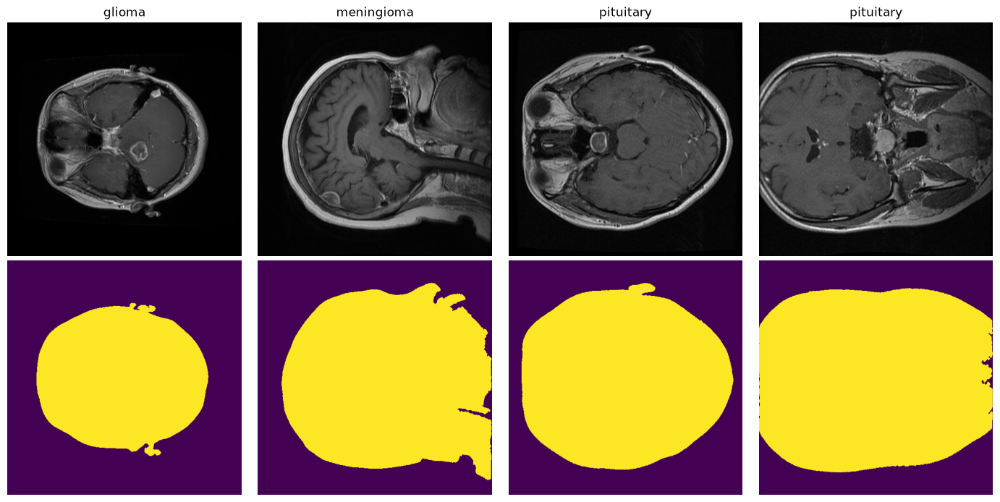

In [33]:
def load_case(row):
    img = np.array(Image.open(row["image_path"]).convert("RGB"))
    gt  = np.array(Image.open(row["mask_path"]).convert("L")) > 0
    x = tf.image.resize(img.astype(np.float32), (224, 224)).numpy()
    x = tf.keras.applications.resnet50.preprocess_input(x.copy())[None]
    return img, gt, x

def brain_mask(img_rgb, frac=0.08):
    """Foreground (head/brain) mask: threshold, keep largest blob, fill holes. Check it visually!"""
    g = img_rgb[..., 0].astype(np.float32)
    m = g > frac * g.max()
    m = ndi.binary_opening(m, iterations=2)
    lab, n = ndi.label(m)
    if n == 0:
        return np.ones_like(m, dtype=bool)
    sizes = ndi.sum(m, lab, range(1, n + 1))
    m = lab == (1 + int(np.argmax(sizes)))
    return ndi.binary_fill_holes(m)

# quick visual check of the brain mask on 4 validation images
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for i, (_, r) in enumerate(val_df.sample(4, random_state=1).iterrows()):
    img, gt, _ = load_case(r)
    ax[0, i].imshow(img); ax[0, i].set_title(r["class_name"]); ax[0, i].axis("off")
    ax[1, i].imshow(brain_mask(img)); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

## 7. Localization metrics and diagnosis of the classification-only ResNet50 (Part B)
Metrics: pointing game, energy-in-mask, pixel-AUC, fixed-area Dice. The validation subset (200 images) picks the layer/method; this also produces the *before* table used in Section 9.

In [34]:
FRACS = [0.01, 0.02, 0.03, 0.05, 0.08]      # fixed-area budgets (fraction of brain pixels)

def dice(a, b):
    s = a.sum() + b.sum()
    return 2.0 * np.logical_and(a, b).sum() / s if s > 0 else 1.0

def localization_metrics(heat, gt, brain=None):
    if brain is not None:
        heat = heat * brain
    region = brain if brain is not None else np.ones_like(gt, dtype=bool)
    out = {}
    out["energy_in_mask"] = float(heat[gt].sum() / (heat.sum() + 1e-8))
    py, px = np.unravel_index(np.argmax(heat), heat.shape)
    gt_dil = ndi.binary_dilation(gt, iterations=10)          # 10-px tolerance
    out["pointing_hit"] = float(gt_dil[py, px])
    y, s = gt[region], heat[region]
    out["pixel_auc"] = float(roc_auc_score(y, s)) if 0 < y.sum() < y.size else np.nan
    flat = np.sort(heat[region])[::-1]
    for f in FRACS:
        k = max(1, int(f * region.sum()))
        thr = flat[min(k, len(flat)) - 1]
        out[f"dice_top{int(f*100)}"] = float(dice(heat >= thr, gt))
    return out

def run_eval(df, tag, n=None, seed=0):
    d = df.sample(n, random_state=seed) if n else df
    rows = []
    for _, r in tqdm(d.iterrows(), total=len(d), desc=tag):
        img, gt, x = load_case(r)
        brain = brain_mask(img)
        maps, cidx, probs = explainer(x)                  # explains the PREDICTED class
        for layer, mm in maps.items():
            for method, cam in mm.items():
                heat = upsample(cam)
                for masked in (False, True):
                    m = localization_metrics(heat, gt, brain if masked else None)
                    rows.append(dict(sample_id=r["sample_id"], true=r["class_name"],
                                     pred=CLASS_NAMES[cidx], correct=CLASS_NAMES[cidx] == r["class_name"],
                                     layer=layer, method=method, brain_masked=masked,
                                     gt_pixels=int(gt.sum()), **m))
    return pd.DataFrame(rows)

# Validation subset (200 images, ~10-15 min on CPU). Increase n for the final run.
val_res = run_eval(val_df, "val", n=200)
val_res.to_csv(OUT_DIR / "val_localization_v2.csv", index=False)
summary = (val_res.groupby(["layer", "method", "brain_masked"])
           [["energy_in_mask", "pointing_hit", "pixel_auc", "dice_top3", "dice_top5"]].mean().round(3))
display(summary.sort_values("pixel_auc", ascending=False))

val:   0%|          | 0/200 [00:00<?, ?it/s]

energy_in_mask  pointing_hit  \
layer            method    brain_masked                                 
conv5_block3_out gradcampp False                  0.039         0.190   
                 layercam  False                  0.039         0.190   
conv4_block6_out gradcampp False                  0.019         0.165   
conv5_block3_out gradcampp True                   0.049         0.190   
                 layercam  True                   0.049         0.190   
                 hirescam  False                  0.046         0.190   
                 gradcam   False                  0.046         0.190   
conv3_block4_out gradcampp False                  0.016         0.005   
                           True                   0.035         0.070   
                 layercam  False                  0.040         0.335   
conv4_block6_out gradcampp True                   0.037         0.195   
conv5_block3_out gradcam   True                   0.063         0.190   
                 hirescam  True                   0.063         0.190   
conv4_block6_out layercam  False                  0.036         0.315   
                 gradcam   False                  0.031         0.210   
conv3_block4_out gradcam   False                  0.035         0.125   
                           True                   0.061         0.135   
                 layercam  True                   0.055         0.340   
conv4_block6_out gradcam   True                   0.061         0.225   
conv3_block4_out hirescam  False                  0.049         0.210   
conv4_block6_out hirescam  False                  0.051         0.220   
                 layercam  True                   0.049         0.315   
conv3_block4_out hirescam  True                   0.068         0.210   
conv4_block6_out hirescam  True                   0.076         0.220   

                                         pixel_auc  dice_top3  dice_top5  
layer            method    brain_masked                                   
conv5_block3_out gradcampp False             0.881      0.111      0.122  
                 layercam  False             0.881      0.111      0.122  
conv4_block6_out gradcampp False             0.764      0.136      0.127  
conv5_block3_out gradcampp True              0.762      0.089      0.103  
                 layercam  True              0.761      0.088      0.103  
                 hirescam  False             0.734      0.112      0.119  
                 gradcam   False             0.734      0.112      0.119  
conv3_block4_out gradcampp False             0.720      0.028      0.038  
                           True              0.688      0.064      0.078  
                 layercam  False             0.647      0.103      0.097  
conv4_block6_out gradcampp True              0.641      0.128      0.146  
conv5_block3_out gradcam   True              0.627      0.086      0.103  
                 hirescam  True              0.627      0.086      0.103  
conv4_block6_out layercam  False             0.624      0.087      0.085  
                 gradcam   False             0.610      0.119      0.106  
conv3_block4_out gradcam   False             0.588      0.065      0.062  
                           True              0.582      0.078      0.087  
                 layercam  True              0.579      0.100      0.103  
conv4_block6_out gradcam   True              0.576      0.125      0.135  
conv3_block4_out hirescam  False             0.569      0.077      0.074  
conv4_block6_out hirescam  False             0.566      0.083      0.079  
                 layercam  True              0.552      0.077      0.085  
conv3_block4_out hirescam  True              0.543      0.076      0.082  
conv4_block6_out hirescam  True              0.540      0.081      0.088

## 8. Multi-task ResNet50-UNet: classification + tumor segmentation (Part C)
A classification-only network has no reason to look at the tumor, so segmentation is supervised with the existing masks. Same ResNet50 encoder, so the comparison stays fair. Training is two-stage (decoder + head, then end-to-end fine-tuning).

In [35]:
from tensorflow.keras import layers, models

IMG = 224
BATCH = 8

def conv_block(x, f):
    for _ in range(2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x

def build_multitask(weights="imagenet", n_cls=3):
    inp = layers.Input((IMG, IMG, 3), name="mri_input")
    bb = tf.keras.applications.ResNet50(include_top=False, weights=weights, input_tensor=inp)
    skips = [bb.get_layer(n).output for n in
             ["conv1_relu", "conv2_block3_out", "conv3_block4_out", "conv4_block6_out"]]
    bott = bb.get_layer("conv5_block3_out").output            # 7x7x2048

    c = layers.GlobalAveragePooling2D(name="gap")(bott)
    c = layers.Dropout(0.3)(c)
    cls = layers.Dense(n_cls, activation="softmax", name="cls")(c)

    d = bott
    for skip, f in zip(reversed(skips), [256, 128, 64, 32]):   # 7->14->28->56->112
        d = layers.UpSampling2D(2, interpolation="bilinear")(d)
        d = layers.Concatenate()([d, skip])
        d = conv_block(d, f)
    d = layers.UpSampling2D(2, interpolation="bilinear")(d)    # 112 -> 224
    d = conv_block(d, 16)
    seg = layers.Conv2D(1, 1, activation="sigmoid", name="seg")(d)
    return models.Model(inp, [cls, seg], name="resnet50_unet_multitask")

def dice_coef(y_true, y_pred, smooth=1.0):
    y_true = tf.reshape(y_true, [tf.shape(y_true)[0], -1])
    y_pred = tf.reshape(y_pred, [tf.shape(y_pred)[0], -1])
    inter = tf.reduce_sum(y_true * y_pred, axis=1)
    return tf.reduce_mean((2 * inter + smooth) /
                          (tf.reduce_sum(y_true, 1) + tf.reduce_sum(y_pred, 1) + smooth))

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1.0 - dice_coef(y_true, y_pred))

CLASS_TO_INDEX = {n: i for i, n in enumerate(CLASS_NAMES)}

def make_ds(frame, training):
    paths = frame["image_path"].astype(str).to_numpy()
    masks = frame["mask_path"].astype(str).to_numpy()
    labels = frame["class_name"].map(CLASS_TO_INDEX).to_numpy().astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, masks, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=42, reshuffle_each_iteration=True)

    def _load(p, m, y):
        img = tf.image.resize(tf.io.decode_png(tf.io.read_file(p), channels=3), (IMG, IMG))
        msk = tf.image.resize(tf.io.decode_png(tf.io.read_file(m), channels=1), (IMG, IMG), method="nearest")
        msk = tf.cast(msk > 0, tf.float32)
        img = tf.cast(img, tf.float32)
        if training:                                   # light, mask-consistent augmentation
            flip = tf.random.uniform(()) > 0.5
            img = tf.cond(flip, lambda: tf.image.flip_left_right(img), lambda: img)
            msk = tf.cond(flip, lambda: tf.image.flip_left_right(msk), lambda: msk)
            img = tf.clip_by_value(img * tf.random.uniform((), 0.85, 1.15), 0.0, 255.0)
        img = tf.keras.applications.resnet50.preprocess_input(img)
        return img, {"cls": y, "seg": msk}

    return ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_df = meta[meta.split == "train"]
train_ds = make_ds(train_df, True)
val_ds   = make_ds(val_df, False)
test_ds  = make_ds(test_df, False)

mt = build_multitask()
mt.summary(line_length=100)

Model: "resnet50_unet_multitask"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ mri_input (InputLayer)      │ (None, 224, 224, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv1_pad (ZeroPadding2D)   │ (None, 230, 230, 3)     │              0 │ mri_input[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv1_conv (Conv2D)         │ (None, 112, 112, 64)    │          9,472 │ conv1_pad[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv1_bn                    │ (None, 112, 112, 64)    │            256 │ conv1_conv[0][0]        │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv1_relu (Activation)     │ (None, 112, 112, 64)    │              0 │ conv1_bn[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ pool1_pad (ZeroPadding2D)   │ (None, 114, 114, 64)    │              0 │ conv1_relu[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ pool1_pool (MaxPooling2D)   │ (None, 56, 56, 64)      │              0 │ pool1_pad[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_1_conv         │ (None, 56, 56, 64)      │          4,160 │ pool1_pool[0][0]        │
│ (Conv2D)                    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_1_bn           │ (None, 56, 56, 64)      │            256 │ conv2_block1_1_conv[0]… │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_1_relu         │ (None, 56, 56, 64)      │              0 │ conv2_block1_1_bn[0][0] │
│ (Activation)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_2_conv         │ (None, 56, 56, 64)      │         36,928 │ conv2_block1_1_relu[0]… │
│ (Conv2D)                    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_2_bn           │ (None, 56, 56, 64)      │            256 │ conv2_block1_2_conv[0]… │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_2_relu         │ (None, 56, 56, 64)      │              0 │ conv2_block1_2_bn[0][0] │
│ (Activation)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_0_conv         │ (None, 56, 56, 256)     │         16,640 │ pool1_pool[0][0]        │
│ (Conv2D)                    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2_block1_3_conv         │ (None, 56, 56, 256)     │    

 Total params: 32,608,788 (124.39 MB)

 Trainable params: 32,553,684 (124.18 MB)

 Non-trainable params: 55,104 (215.25 KB)

In [36]:
MT_DIR = PROJECT_DIR / "models" / "resnet50_multitask"
MT_DIR.mkdir(parents=True, exist_ok=True)
BEST = MT_DIR / "multitask_best.keras"

def compile_mt(lr):
    mt.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss={"cls": "sparse_categorical_crossentropy", "seg": bce_dice_loss},
        loss_weights={"cls": 1.0, "seg": 1.0},
        metrics={"cls": ["accuracy"], "seg": [dice_coef]},
    )

# keep encoder BatchNorm frozen (batch size 8 on CPU makes BN statistics noisy)
enc_layers = [l for l in mt.layers if l.name.startswith(("conv1", "conv2", "conv3", "conv4", "conv5", "pool1"))]
for l in enc_layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

# Stage 1: warm up decoder + head with the encoder frozen
for l in enc_layers: l.trainable = False
compile_mt(1e-3)
cb = lambda: [
    tf.keras.callbacks.ModelCheckpoint(str(BEST), monitor="val_loss", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.CSVLogger(str(MT_DIR / "multitask_history.csv"), append=True),
]
h1 = mt.fit(train_ds, validation_data=val_ds, epochs=6, callbacks=cb())

# Stage 2: unfreeze encoder (except BN) and fine-tune end-to-end
for l in enc_layers:
    l.trainable = not isinstance(l, layers.BatchNormalization)
compile_mt(3e-5)
h2 = mt.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cb())

Epoch 1/6


C:\Users\lokes\.conda\envs\brainxai\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - cls_accuracy: 0.7495 - cls_loss: 0.6197 - loss: 1.9700 - seg_dice_coef: 0.0360 - seg_loss: 1.3489
Epoch 1: val_loss improved from None to 1.51600, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50_multitask\multitask_best.keras

Epoch 1: finished saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50_multitask\multitask_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 397s 1s/step - cls_accuracy: 0.7495 - cls_loss: 0.6197 - loss: 1.9700 - seg_dice_coef: 0.0360 - seg_loss: 1.3489 - val_cls_accuracy: 0.8697 - val_cls_loss: 0.3494 - val_loss: 1.5160 - val_seg_dice_coef: 0.0429 - val_seg_loss: 1.1635
Epoch 2/6
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - cls_accuracy: 0.8551 - cls_loss: 0.3760 - loss: 1.4456 - seg_dice_coef: 0.0569 - seg_loss: 1.0693
Epoch 2: val_loss improved from 1.51600 to 1.26985, saving model to C:\Users\lokes\Documents\BrainTumor_XAI_Restart\models\resnet50_multitask\multitask_best.k

## 9. Multi-task test evaluation, failure analysis, validation-tuned Dice gains, CIs, before/after heat-maps, tumor ablation (Part D and next steps)
Run once, after the models are final.

In [37]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

mt = tf.keras.models.load_model(BEST, custom_objects={"bce_dice_loss": bce_dice_loss, "dice_coef": dice_coef})

y_true, y_pred, dices, ious, ids = [], [], [], [], []
test_paths = test_df.reset_index(drop=True)
i = 0
for xb, yb in test_ds:
    p_cls, p_seg = mt.predict(xb, verbose=0)
    for k in range(len(p_cls)):
        pred_mask = p_seg[k, ..., 0] > 0.5
        gt = yb["seg"][k, ..., 0].numpy() > 0.5
        inter = np.logical_and(pred_mask, gt).sum()
        union = np.logical_or(pred_mask, gt).sum()
        dices.append(dice(pred_mask, gt)); ious.append(inter / union if union else 1.0)
        y_true.append(int(yb["cls"][k])); y_pred.append(int(np.argmax(p_cls[k])))

print("=== Classification (test) ===")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
print(pd.DataFrame(confusion_matrix(y_true, y_pred), index=CLASS_NAMES, columns=CLASS_NAMES))
print("\n=== Tumour localization via segmentation head (test) ===")
print(f"Mean Dice: {np.mean(dices):.4f}   Mean IoU: {np.mean(ious):.4f}")
res = pd.DataFrame({"class": [CLASS_NAMES[t] for t in y_true], "dice": dices, "iou": ious})
display(res.groupby("class")[["dice", "iou"]].mean().round(4))
res.to_csv(OUT_DIR / "multitask_test_segmentation.csv", index=False)

=== Classification (test) ===
              precision    recall  f1-score   support

      glioma     0.9330    0.9330    0.9330       224
  meningioma     0.8761    0.8534    0.8646       116
   pituitary     0.9013    0.9195    0.9103       149

    accuracy                         0.9100       489
   macro avg     0.9035    0.9020    0.9027       489
weighted avg     0.9099    0.9100    0.9099       489

            glioma  meningioma  pituitary
glioma         209          14          1
meningioma       3          99         14
pituitary       12           0        137

=== Tumour localization via segmentation head (test) ===
Mean Dice: 0.7183   Mean IoU: 0.6080


,dice,iou
class,,
glioma,0.6141,0.4910
meningioma,0.8827,0.8019
pituitary,0.7468,0.6330


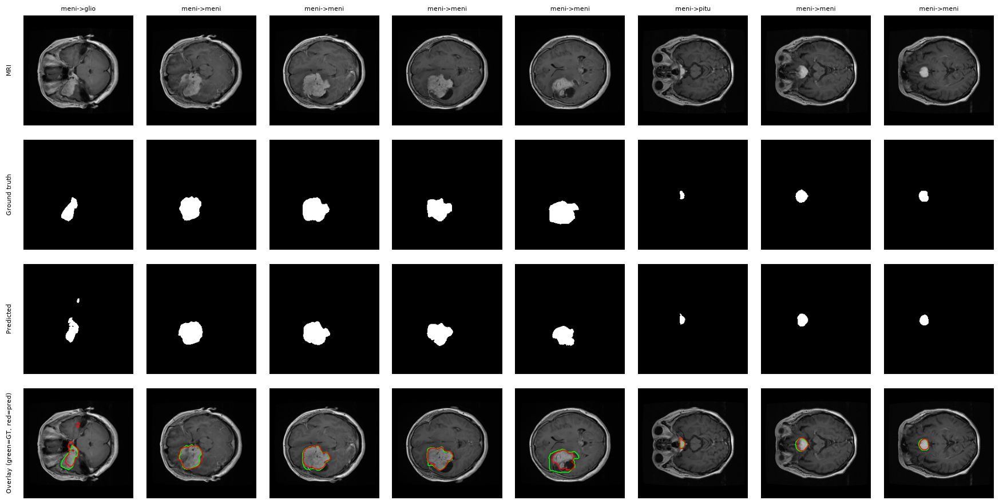

In [38]:
# Overlay figure for the report: MRI | ground truth | predicted mask | contour overlay
batch_x, batch_y = next(iter(test_ds))
pc, ps = mt.predict(batch_x, verbose=0)
fig, ax = plt.subplots(4, len(pc), figsize=(2.2 * len(pc), 9), squeeze=False)
for k in range(len(pc)):
    im = np.array(Image.open(test_df.iloc[k]["image_path"]).convert("L").resize((IMG, IMG)))
    ax[0, k].imshow(im, cmap="gray"); ax[0, k].set_title(f"{CLASS_NAMES[int(batch_y['cls'][k])][:4]}->{CLASS_NAMES[int(np.argmax(pc[k]))][:4]}", fontsize=8)
    ax[1, k].imshow(batch_y["seg"][k, ..., 0], cmap="gray")
    ax[2, k].imshow(ps[k, ..., 0] > 0.5, cmap="gray")
    ax[3, k].imshow(im, cmap="gray")
    ax[3, k].contour(batch_y["seg"][k, ..., 0], levels=[0.5], colors="lime", linewidths=1)
    ax[3, k].contour(ps[k, ..., 0], levels=[0.5], colors="red", linewidths=1)
    for a in ax[:, k]: a.axis("off")
for r, t in enumerate(["MRI", "Ground truth", "Predicted", "Overlay (green=GT, red=pred)"]):
    ax[r, 0].text(-0.1, 0.5, t, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "multitask_overlays.png", dpi=200); plt.show()

Mean Dice  : 0.7183 | Median Dice: 0.8014
Dice < 0.10 (complete misses): 4.7%
Dice < 0.50                  : 16.0%
Dice >= 0.80                 : 50.1%

By class:


,count,mean,50%,min
class,,,,
glioma,224.0,0.614,0.704,0.000
meningioma,116.0,0.883,0.918,0.414
pituitary,149.0,0.747,0.817,0.000


By classification correctness:


,count,mean
correct,,
False,44,0.651
True,445,0.725


Spearman(Dice, tumour size): 0.123


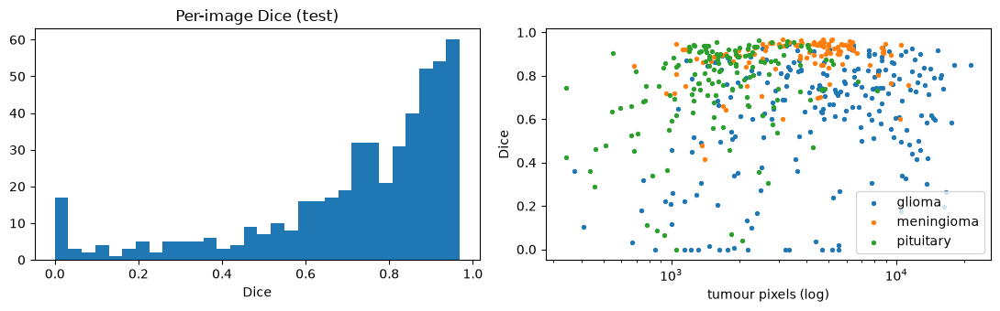

In [39]:
res = pd.DataFrame({
    "sample_id": test_df["sample_id"].values, "patient_id": test_df["patient_id"].values,
    "class": [CLASS_NAMES[t] for t in y_true], "pred": [CLASS_NAMES[p] for p in y_pred],
    "dice": dices, "iou": ious, "tumour_px": test_df["tumor_pixels"].values,
})
res["correct"] = res["class"] == res["pred"]
print("Mean Dice  :", round(res.dice.mean(), 4), "| Median Dice:", round(res.dice.median(), 4))
print("Dice < 0.10 (complete misses):", f"{(res.dice < 0.10).mean():.1%}")
print("Dice < 0.50                  :", f"{(res.dice < 0.50).mean():.1%}")
print("Dice >= 0.80                 :", f"{(res.dice >= 0.80).mean():.1%}")
print("\nBy class:")
display(res.groupby("class").dice.describe()[["count", "mean", "50%", "min"]].round(3))
print("By classification correctness:")
display(res.groupby("correct").dice.agg(["count", "mean"]).round(3))
from scipy.stats import spearmanr
print("Spearman(Dice, tumour size):", round(spearmanr(res.dice, res.tumour_px)[0], 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(res.dice, bins=30); ax[0].set_title("Per-image Dice (test)"); ax[0].set_xlabel("Dice")
for c in CLASS_NAMES:
    ax[1].scatter(res[res["class"] == c].tumour_px, res[res["class"] == c].dice, s=8, label=c)
ax[1].set_xscale("log"); ax[1].set_xlabel("tumour pixels (log)"); ax[1].set_ylabel("Dice"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "seg_failure_analysis.png", dpi=200); plt.show()
res.to_csv(OUT_DIR / "multitask_test_per_image.csv", index=False)

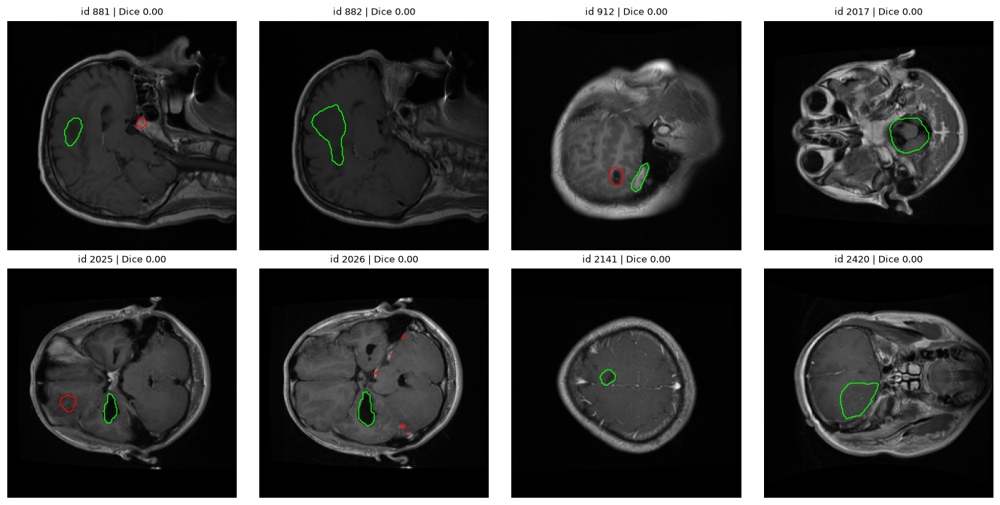

In [40]:
# Look at the 8 worst glioma cases (green = ground truth, red = prediction)
worst = res[res["class"] == "glioma"].nsmallest(8, "dice").index.tolist()
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, i in zip(ax.flat, worst):
    row = test_df.iloc[i]
    img = np.array(Image.open(row["image_path"]).convert("RGB"))
    x = tf.keras.applications.resnet50.preprocess_input(tf.image.resize(img.astype(np.float32), (224, 224)).numpy())[None]
    ps = mt.predict(x, verbose=0)[1][0, ..., 0]
    gt = np.array(Image.open(row["mask_path"]).convert("L").resize((224, 224), Image.NEAREST)) > 0
    a.imshow(np.array(Image.fromarray(img).resize((224, 224))), cmap="gray")
    a.contour(gt, levels=[0.5], colors="lime", linewidths=1); a.contour(ps, levels=[0.5], colors="red", linewidths=1)
    a.set_title(f"id {row['sample_id']} | Dice {res.dice[i]:.2f}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

In [41]:
def predict_seg(df, tta=False):
    ds = make_ds(df, False)
    P, G = [], []
    for xb, yb in ds:
        p = mt.predict(xb, verbose=0)[1][..., 0]
        if tta:
            pf = mt.predict(tf.reverse(xb, axis=[2]), verbose=0)[1][..., 0][:, :, ::-1]
            p = 0.5 * (p + pf)
        P.append(p); G.append(yb["seg"].numpy()[..., 0] > 0.5)
    return np.concatenate(P), np.concatenate(G)

def largest_cc(m):
    lab, n = ndi.label(m)
    if n <= 1: return m
    sizes = ndi.sum(m, lab, range(1, n + 1))
    return lab == (1 + int(np.argmax(sizes)))

def mean_dice(P, G, thr, cc):
    out = []
    for p, g in zip(P, G):
        m = p > thr
        if cc and m.any(): m = largest_cc(m)
        out.append(dice(m, g))
    return float(np.mean(out))

Pv, Gv = predict_seg(val_df)
Pv_t, _ = predict_seg(val_df, tta=True)
grid = []
for tta, P in [(False, Pv), (True, Pv_t)]:
    for cc in (False, True):
        for thr in (0.3, 0.4, 0.5, 0.6):
            grid.append(dict(tta=tta, largest_cc=cc, thr=thr, val_dice=mean_dice(P, Gv, thr, cc)))
grid = pd.DataFrame(grid).sort_values("val_dice", ascending=False)
display(grid.head(8).round(4))
best = grid.iloc[0]
print("Chosen on validation:", dict(best))

Pt, Gt = predict_seg(test_df, tta=bool(best.tta))
print(f"\nTEST mean Dice with chosen settings: {mean_dice(Pt, Gt, best.thr, bool(best.largest_cc)):.4f}  (baseline 0.7380)")

,tta,largest_cc,thr,val_dice
12,True,True,0.3,0.7497
13,True,True,0.4,0.7494
4,False,True,0.3,0.7474
5,False,True,0.4,0.7463
6,False,True,0.5,0.7438
9,True,False,0.4,0.7426
7,False,True,0.6,0.7407
14,True,True,0.5,0.7405


Chosen on validation: {'tta': np.True_, 'largest_cc': np.True_, 'thr': np.float64(0.3), 'val_dice': np.float64(0.7497483144283869)}

TEST mean Dice with chosen settings: 0.7383  (baseline 0.7380)


In [42]:
rng = np.random.default_rng(0)
pids = res["patient_id"].unique()
groups = {p: res.index[res.patient_id == p].values for p in pids}
acc, md_ = [], []
for _ in range(2000):
    idx = np.concatenate([groups[p] for p in rng.choice(pids, len(pids), replace=True)])
    acc.append(res.correct.values[idx].mean()); md_.append(res.dice.values[idx].mean())
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
print(f"Accuracy   : {res.correct.mean():.4f}  95% CI [{ci(acc)[0]:.3f}, {ci(acc)[1]:.3f}]")
print(f"Mean Dice  : {res.dice.mean():.4f}  95% CI [{ci(md_)[0]:.3f}, {ci(md_)[1]:.3f}]")

Accuracy   : 0.9100  95% CI [0.835, 0.969]
Mean Dice  : 0.7183  95% CI [0.670, 0.772]


In [43]:
def fast_metrics(heat, gt, gt_dil, brain, masked):
    if masked: heat = heat * brain
    region = brain if masked else np.ones_like(gt, dtype=bool)
    out = {"energy_in_mask": float(heat[gt].sum() / (heat.sum() + 1e-8))}
    py, px = np.unravel_index(np.argmax(heat), heat.shape)
    out["pointing_hit"] = float(gt_dil[py, px])
    y, s = gt[region], heat[region]
    out["pixel_auc"] = float(roc_auc_score(y, s)) if 0 < y.sum() < y.size else np.nan
    flat = np.sort(s)[::-1]
    for f in FRACS:
        k = max(1, int(f * region.sum()))
        out[f"dice_top{int(f*100)}"] = float(dice(heat >= flat[min(k, len(flat)) - 1], gt))
    return out

def run_eval2(df, expl, tag, n=200, seed=0, methods=("gradcam", "layercam", "gradcampp")):
    d = df.sample(n, random_state=seed)
    rows = []
    for _, r in tqdm(d.iterrows(), total=len(d), desc=tag):
        img, gt, x = load_case(r)
        brain = brain_mask(img)
        gt_dil = ndi.binary_dilation(gt, iterations=10)
        maps, cidx, probs = expl(x)
        for layer, mm in maps.items():
            for method in methods:
                heat = upsample(mm[method])
                for masked in (False, True):
                    rows.append(dict(sample_id=r["sample_id"], correct=CLASS_NAMES[cidx] == r["class_name"],
                                     layer=layer, method=method, brain_masked=masked,
                                     **fast_metrics(heat, gt, gt_dil, brain, masked)))
    return pd.DataFrame(rows)

mt_expl = CamExplainer(mt, mt.get_layer("cls"), ["conv3_block4_out", "conv4_block6_out", "conv5_block3_out"])
after_res = run_eval2(val_df, mt_expl, "after (multi-task)", n=200)
after_res.to_csv(OUT_DIR / "val_localization_after_multitask.csv", index=False)

keys = ["layer", "method", "brain_masked"]; cols = ["energy_in_mask", "pointing_hit", "pixel_auc", "dice_top5"]
before = val_res.groupby(keys)[cols].mean().add_suffix("_before")
after  = after_res.groupby(keys)[cols].mean().add_suffix("_after")
cmp_ = before.join(after, how="inner").round(3)
display(cmp_.sort_values("pointing_hit_after", ascending=False))
cmp_.to_csv(OUT_DIR / "before_after_xai_comparison.csv")

after (multi-task):   0%|          | 0/200 [00:00<?, ?it/s]

energy_in_mask_before  \
layer            method    brain_masked                          
conv3_block4_out layercam  False                         0.040   
                           True                          0.055   
conv4_block6_out gradcampp False                         0.019   
                           True                          0.037   
                 layercam  True                          0.049   
                           False                         0.036   
                 gradcam   True                          0.061   
                           False                         0.031   
conv3_block4_out gradcampp True                          0.035   
conv5_block3_out layercam  False                         0.039   
                           True                          0.049   
                 gradcampp False                         0.039   
                           True                          0.049   
                 gradcam   True                          0.063   
                           False                         0.046   
conv3_block4_out gradcam   True                          0.061   
                           False                         0.035   
                 gradcampp False                         0.016   

                                         pointing_hit_before  \
layer            method    brain_masked                        
conv3_block4_out layercam  False                       0.335   
                           True                        0.340   
conv4_block6_out gradcampp False                       0.165   
                           True                        0.195   
                 layercam  True                        0.315   
                           False                       0.315   
                 gradcam   True                        0.225   
                           False                       0.210   
conv3_block4_out gradcampp True                        0.070   
conv5_block3_out layercam  False                       0.190   
                           True                        0.190   
                 gradcampp False                       0.190   
                           True                        0.190   
                 gradcam   True                        0.190   
                           False                       0.190   
conv3_block4_out gradcam   True                        0.135   
                           False                       0.125   
                 gradcampp False                       0.005   

                                         pixel_auc_before  dice_top5_before  \
layer            method    brain_masked                                       
conv3_block4_out layercam  False                    0.647             0.097   
                           True                     0.579             0.103   
conv4_block6_out gradcampp False                    0.764             0.127   
                           True                     0.641             0.146   
                 layercam  True                     0.552             0.085   
                           False                    0.624             0.085   
                 gradcam   True                     0.576             0.135   
                           False                    0.610             0.106   
conv3_block4_out gradcampp True                     0.688             0.078   
conv5_block3_out layercam  False                    0.881             0.122   
                           True                     0.761             0.103   
                 gradcampp False                    0.881             0.122   
                           True                     0.762             0.103   
                 gradcam   True                     0.627             0.103   
                           False                    0.734             0.119   
conv3_block4_out gradcam   True                     0.582             0.087   
                 

In [44]:
from scipy.stats import wilcoxon

def prep(batch_uint8):
    x = tf.image.resize(batch_uint8.astype(np.float32), (224, 224)).numpy()
    return tf.keras.applications.resnet50.preprocess_input(x)

def control_patch(t, brain, rng, tries=80):
    h, w = t.shape
    far = ndi.binary_dilation(t, iterations=15)
    for _ in range(tries):
        sh = np.roll(np.roll(t, int(rng.integers(-h // 2, h // 2)), 0), int(rng.integers(-w // 2, w // 2)), 1)
        if (sh & brain).sum() >= 0.95 * sh.sum() and not (sh & far).any():
            return sh
    return None

def tumour_ablation(df, predict_fn, tag, n=150, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for _, r in tqdm(df.sample(n, random_state=seed).iterrows(), total=n, desc=tag):
        img = np.array(Image.open(r["image_path"]).convert("RGB"))
        gt = np.array(Image.open(r["mask_path"]).convert("L")) > 0
        brain = brain_mask(img)
        t = ndi.binary_dilation(gt, iterations=5)
        c = control_patch(t, brain, rng)
        if c is None: continue
        fill = np.median(img[..., 0][brain & ~t])
        a, b = img.copy(), img.copy()
        a[t] = fill; b[c] = fill
        p = predict_fn(prep(np.stack([img, a, b])))
        k = int(np.argmax(p[0]))
        rows.append(dict(correct=CLASS_NAMES[k] == r["class_name"], p0=p[0, k], p_tumour=p[1, k], p_control=p[2, k],
                         flip_tumour=int(np.argmax(p[1]) != k), flip_control=int(np.argmax(p[2]) != k)))
    d = pd.DataFrame(rows)
    d["drop_tumour"] = d.p0 - d.p_tumour; d["drop_control"] = d.p0 - d.p_control
    print(f"\n[{tag}] n={len(d)}")
    print(f"  mean prob drop  tumour-removed: {d.drop_tumour.mean():.3f} | control-removed: {d.drop_control.mean():.3f}")
    print(f"  prediction flips tumour-removed: {d.flip_tumour.mean():.1%} | control-removed: {d.flip_control.mean():.1%}")
    print(f"  Wilcoxon (paired) p-value: {wilcoxon(d.drop_tumour, d.drop_control).pvalue:.2e}")
    return d

base_fn = lambda x: model.predict(x, verbose=0)          # original ResNet50 classifier
mt_fn   = lambda x: mt.predict(x, verbose=0)[0]          # multi-task classifier
abl_base = tumour_ablation(test_df, base_fn, "ResNet50 (classification only)")
abl_mt   = tumour_ablation(test_df, mt_fn,   "ResNet50-UNet (multi-task)")
abl_base.to_csv(OUT_DIR / "ablation_resnet50.csv", index=False); abl_mt.to_csv(OUT_DIR / "ablation_multitask.csv", index=False)

ResNet50 (classification only):   0%|          | 0/150 [00:00<?, ?it/s]


[ResNet50 (classification only)] n=149
  mean prob drop  tumour-removed: 0.055 | control-removed: 0.010
  prediction flips tumour-removed: 6.0% | control-removed: 2.7%
  Wilcoxon (paired) p-value: 2.30e-04


ResNet50-UNet (multi-task):   0%|          | 0/150 [00:00<?, ?it/s]


[ResNet50-UNet (multi-task)] n=149
  mean prob drop  tumour-removed: 0.124 | control-removed: 0.005
  prediction flips tumour-removed: 14.8% | control-removed: 2.0%
  Wilcoxon (paired) p-value: 3.76e-05


## 10. Final evaluation (no more model changes)
10.1 paired classification test (baseline vs multi-task); 10.2 paired ablation comparison; 10.3 final heat-map evaluation on the TEST set with the configuration frozen on validation (`conv4_block6_out`, Grad-CAM++); 10.4 qualitative figure.

In [45]:
from scipy.stats import binomtest, wilcoxon

P_base = np.concatenate([model.predict(xb, verbose=0) for xb, _ in make_ds(test_df, False)])
pred_base, pred_mt, y = P_base.argmax(1), np.array(y_pred), np.array(y_true)
print(f"Sanity check, baseline test accuracy: {(pred_base == y).mean():.4f}  (should be ~0.8630)")

cb, cm = pred_base == y, pred_mt == y
b, c = int((cb & ~cm).sum()), int((~cb & cm).sum())
print(f"Baseline right & multi-task wrong: {b} | baseline wrong & multi-task right: {c}")
print(f"McNemar exact p-value (ignores patient clustering): {binomtest(b, b + c, 0.5).pvalue:.4f}")

rng = np.random.default_rng(0)
pids = test_df["patient_id"].values; up = np.unique(pids)
groups = {p: np.where(pids == p)[0] for p in up}
diffs = []
for _ in range(5000):
    idx = np.concatenate([groups[p] for p in rng.choice(up, len(up), replace=True)])
    diffs.append(cm[idx].mean() - cb[idx].mean())
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Accuracy gain (multi-task - baseline): {cm.mean() - cb.mean():+.4f}  patient-level 95% CI [{lo:+.3f}, {hi:+.3f}]")
print(f"Share of bootstrap samples where multi-task is better: {np.mean(np.array(diffs) > 0):.1%}")

Sanity check, baseline test accuracy: 0.8528  (should be ~0.8630)
Baseline right & multi-task wrong: 10 | baseline wrong & multi-task right: 38
McNemar exact p-value (ignores patient clustering): 0.0001
Accuracy gain (multi-task - baseline): +0.0573  patient-level 95% CI [+0.012, +0.108]
Share of bootstrap samples where multi-task is better: 99.4%


In [46]:
assert len(abl_base) == len(abl_mt), "Row counts differ; the paired test below would be invalid"
net_base = abl_base.drop_tumour - abl_base.drop_control
net_mt   = abl_mt.drop_tumour   - abl_mt.drop_control
print(f"Net tumour effect (tumour-removed drop minus control drop): baseline {net_base.mean():.3f} | multi-task {net_mt.mean():.3f}")
print(f"Flip rate, tumour-removed: baseline {abl_base.flip_tumour.mean():.1%} | multi-task {abl_mt.flip_tumour.mean():.1%}")
print(f"Paired Wilcoxon, multi-task vs baseline net effect: p = {wilcoxon(net_mt, net_base).pvalue:.4f}")
print("Among correctly classified images only:")
for name, d in [("baseline", abl_base), ("multi-task", abl_mt)]:
    s = d[d.correct]
    print(f"  {name:10s} n={len(s)} drop_tumour={s.drop_tumour.mean():.3f} drop_control={s.drop_control.mean():.3f} flips={s.flip_tumour.mean():.1%}")

Net tumour effect (tumour-removed drop minus control drop): baseline 0.045 | multi-task 0.119
Flip rate, tumour-removed: baseline 6.0% | multi-task 14.8%
Paired Wilcoxon, multi-task vs baseline net effect: p = 0.1913
Among correctly classified images only:
  baseline   n=128 drop_tumour=0.064 drop_control=0.007 flips=7.0%
  multi-task n=132 drop_tumour=0.131 drop_control=0.003 flips=13.6%


In [47]:
LAYER, METHOD = "conv4_block6_out", "gradcampp"
FEATS = [LAYER, "conv5_block3_out"]          # last entry must be the final backbone output
expl_old = CamExplainer(backbone, model.get_layer("classification_output"), FEATS)
expl_new = CamExplainer(mt, mt.get_layer("cls"), FEATS)

def run_eval3(df, expl, tag):
    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc=tag):
        img, gt, x = load_case(r)
        brain = brain_mask(img)
        gt_dil = ndi.binary_dilation(gt, iterations=10)
        maps, cidx, _ = expl(x)
        heat = upsample(maps[LAYER][METHOD])
        for masked in (False, True):
            rows.append(dict(sample_id=r["sample_id"], patient_id=r["patient_id"], class_name=r["class_name"],
                             correct=CLASS_NAMES[cidx] == r["class_name"], brain_masked=masked,
                             **fast_metrics(heat, gt, gt_dil, brain, masked)))
    return pd.DataFrame(rows)

test_old = run_eval3(test_df, expl_old, "TEST old ResNet50")
test_new = run_eval3(test_df, expl_new, "TEST multi-task")
test_old.to_csv(OUT_DIR / "test_heatmap_old.csv", index=False); test_new.to_csv(OUT_DIR / "test_heatmap_new.csv", index=False)

cols = ["energy_in_mask", "pointing_hit", "pixel_auc", "dice_top3", "dice_top5"]
table = pd.concat({"old ResNet50": test_old.groupby("brain_masked")[cols].mean(),
                   "multi-task": test_new.groupby("brain_masked")[cols].mean()}, names=["model"]).round(3)
display(table)

def patient_boot(df, col, n=2000, seed=0):
    g = {p: v[col].values for p, v in df.groupby("patient_id")}
    keys = list(g); rng = np.random.default_rng(seed)
    m = [np.concatenate([g[k] for k in rng.choice(keys, len(keys))]).mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

for name, d in [("old ResNet50", test_old), ("multi-task", test_new)]:
    s = d[d.brain_masked]
    print(f"{name:13s} pointing_hit {s.pointing_hit.mean():.3f} CI {np.round(patient_boot(s, 'pointing_hit'), 3)} | "
          f"dice_top5 {s.dice_top5.mean():.3f} CI {np.round(patient_boot(s, 'dice_top5'), 3)}")
print("\nBy class (multi-task, brain-masked):")
display(test_new[test_new.brain_masked].groupby("class_name")[cols].mean().round(3))

TEST old ResNet50:   0%|          | 0/489 [00:00<?, ?it/s]

TEST multi-task:   0%|          | 0/489 [00:00<?, ?it/s]

energy_in_mask  pointing_hit  pixel_auc  dice_top3  \
model        brain_masked                                                       
old ResNet50 False                  0.020         0.227      0.791      0.141   
             True                   0.038         0.260      0.683      0.145   
multi-task   False                  0.028         0.485      0.865      0.302   
             True                   0.049         0.485      0.775      0.295   

                           dice_top5  
model        brain_masked             
old ResNet50 False             0.138  
             True              0.156  
multi-task   False             0.262  
             True              0.309

old ResNet50  pointing_hit 0.260 CI [0.174 0.36 ] | dice_top5 0.156 CI [0.105 0.208]
multi-task    pointing_hit 0.485 CI [0.346 0.617] | dice_top5 0.309 CI [0.212 0.398]

By class (multi-task, brain-masked):


,energy_in_mask,pointing_hit,pixel_auc,dice_top3,dice_top5
class_name,,,,,
glioma,0.065,0.567,0.873,0.313,0.351
meningioma,0.067,0.879,0.958,0.609,0.593
pituitary,0.012,0.054,0.484,0.023,0.024


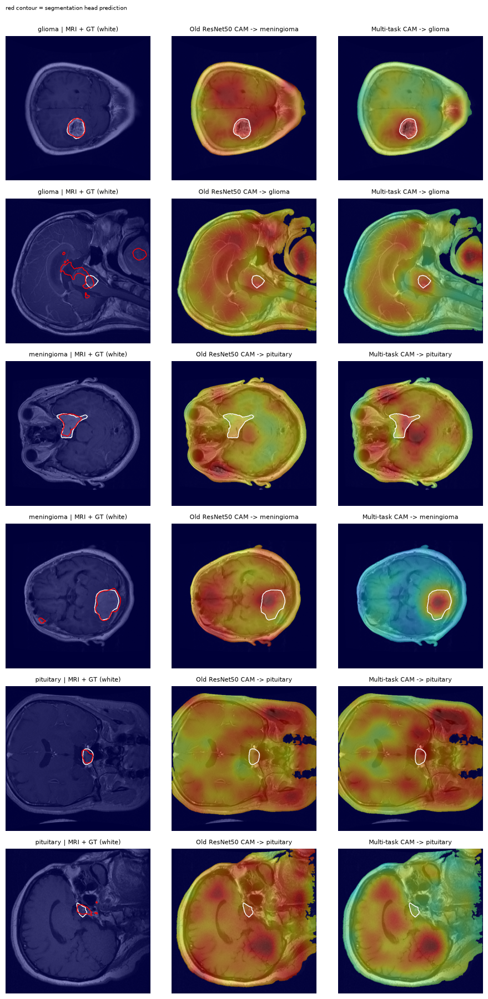

In [48]:
def overlay(ax, img, heat, gt, title, pred_mask=None):
    ax.imshow(img, cmap="gray"); ax.imshow(heat, cmap="jet", alpha=0.45)
    ax.contour(gt, levels=[0.5], colors="white", linewidths=1)
    if pred_mask is not None: ax.contour(pred_mask, levels=[0.5], colors="red", linewidths=1)
    ax.set_title(title, fontsize=8); ax.axis("off")

rng = np.random.default_rng(3)
picks = []
for cname in CLASS_NAMES:
    picks += list(rng.choice(test_df.index[test_df.class_name == cname], 2, replace=False))

fig, ax = plt.subplots(len(picks), 3, figsize=(9, 3 * len(picks)))
for i, k in enumerate(picks):
    r = test_df.loc[k]
    img, gt, x = load_case(r)
    brain = brain_mask(img)
    mo, co, _ = expl_old(x); mn, cn, _ = expl_new(x)
    ho = upsample(mo[LAYER][METHOD]) * brain; hn = upsample(mn[LAYER][METHOD]) * brain
    seg = tf.image.resize(mt.predict(x, verbose=0)[1][0], (512, 512)).numpy()[..., 0] > 0.5
    gray = img[..., 0]
    overlay(ax[i, 0], gray, np.zeros_like(ho), gt, f"{r['class_name']} | MRI + GT (white)", pred_mask=seg)
    overlay(ax[i, 1], gray, ho, gt, f"Old ResNet50 CAM -> {CLASS_NAMES[co]}")
    overlay(ax[i, 2], gray, hn, gt, f"Multi-task CAM -> {CLASS_NAMES[cn]}")
ax[0, 0].text(0.0, 1.18, "red contour = segmentation head prediction", transform=ax[0, 0].transAxes, fontsize=7)
plt.tight_layout(); plt.savefig(OUT_DIR / "qualitative_old_vs_new.png", dpi=200); plt.show()

## 11–17. Consolidation and remaining phases (Phases 9 → 16)
Phase 9 consolidates and re-checks all three classifiers; Phase 10 caches final heat-maps; Phase 11 heat-map → region → bounding box; Phase 12 region vs ground truth; Phase 13 quantitative analysis; Phase 14 robustness; Phase 15 generalization; Phase 16 results. **No model is re-trained below.**
> The cells below define their own helper versions (`load_case`, `upsample`, …) that supersede the earlier ones; this is intended.

In [49]:
# Phase 9 — Cell 1: Environment, paths, reproducibility
import sys, json, time, io, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.stats import spearmanr, wilcoxon
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

print("Python    :", sys.version.split()[0])
print("Executable:", sys.executable)
print("TensorFlow:", tf.__version__)
try:
    print("Keras     :", tf.keras.__version__)
except Exception:
    pass
if not tf.__version__.startswith("2.21"):
    print("\nWARNING: your ResNet50/EfficientNet models were trained with TensorFlow 2.21.0 (conda env 'brainxai').")
    print("         You are running", tf.__version__, "- switch the kernel to 'brainxai' before continuing.")

PROJECT_DIR = Path.home() / "Documents" / "BrainTumor_XAI_Restart"
SPLIT_PATH  = PROJECT_DIR / "data" / "metadata" / "patient_split_metadata.csv"
RESNET_PATH = PROJECT_DIR / "models" / "resnet50" / "resnet50_finetuned_best.keras"
EFFNET_PATH = PROJECT_DIR / "models" / "efficientnetb0" / "efficientnetb0_finetuned_best.keras"
MT_PATH     = PROJECT_DIR / "models" / "resnet50_multitask" / "multitask_best.keras"
CLS_DIR     = PROJECT_DIR / "results" / "classification"
V2_DIR      = PROJECT_DIR / "results" / "localization_v2"
OUT_DIR     = PROJECT_DIR / "results" / "final"
FIG_DIR     = PROJECT_DIR / "results" / "figures"
for d in (OUT_DIR, FIG_DIR): d.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
CLASS_TO_INDEX = {n: i for i, n in enumerate(CLASS_NAMES)}
IMG, ORIG = 224, 512

# ---- run-time knobs -------------------------------------------------------
ROBUST_N = 120      # images used in the robustness study (None = whole test set; ~4x slower)
BOOT_N   = 2000     # patient-level bootstrap resamples
# ---------------------------------------------------------------------------

meta = pd.read_csv(SPLIT_PATH, dtype={"patient_id": str, "sample_id": str})
val_df  = meta[meta.split == "validation"].reset_index(drop=True)
test_df = meta[meta.split == "test"].reset_index(drop=True)
print(f"\nValidation: {len(val_df)} images / {val_df.patient_id.nunique()} patients")
print(f"Test      : {len(test_df)} images / {test_df.patient_id.nunique()} patients")
for p in (RESNET_PATH, EFFNET_PATH, MT_PATH):
    assert p.exists(), f"Missing model file: {p}"
print("All three model files found.")

Python    : 3.11.17
Executable: C:\Users\lokes\.conda\envs\brainxai\python.exe
TensorFlow: 2.21.0
Keras     : 3.15.1

Validation: 491 images / 35 patients
Test      : 489 images / 35 patients
All three model files found.


In [50]:
# Phase 9 — Cell 2: Load the three trained models (inference only)
resnet = tf.keras.models.load_model(RESNET_PATH, compile=False)
effnet = tf.keras.models.load_model(EFFNET_PATH, compile=False)
mt     = tf.keras.models.load_model(MT_PATH, compile=False)
backbone = resnet.get_layer("resnet50")
print("ResNet50      :", resnet.name)
print("EfficientNetB0:", effnet.name)
print("Multi-task    :", mt.name, "| outputs:", [o.name for o in mt.outputs])

ResNet50      : resnet50_classifier
EfficientNetB0: efficientnetb0_classifier
Multi-task    : resnet50_unet_multitask | outputs: ['keras_tensor_4727', 'keras_tensor_4729']


In [51]:
# Phase 9 — Cell 3: Shared helpers (pre-processing, CAM engine, metrics)

# ---------- pre-processing (identical to training) --------------------------
def prep_resnet(img_uint8):
    x = tf.image.resize(img_uint8.astype(np.float32), (IMG, IMG)).numpy()
    return tf.keras.applications.resnet50.preprocess_input(x.copy())[None]

def prep_effnet(img_uint8):
    return tf.image.resize(img_uint8.astype(np.float32), (IMG, IMG)).numpy()[None]   # 0-255, EfficientNet rescales internally

def read_case_raw(row):
    img = np.array(Image.open(row["image_path"]).convert("RGB"))
    gt  = np.array(Image.open(row["mask_path"]).convert("L")) > 0
    if img.shape[:2] != (ORIG, ORIG):                       # safety net, normally never triggered
        img = np.array(Image.fromarray(img).resize((ORIG, ORIG), Image.BILINEAR))
        gt  = np.array(Image.fromarray(gt.astype(np.uint8) * 255).resize((ORIG, ORIG), Image.NEAREST)) > 0
    return img, gt

def brain_mask(img_rgb, frac=0.08):
    g = img_rgb[..., 0].astype(np.float32)
    m = g > frac * g.max()
    m = ndi.binary_opening(m, iterations=2)
    lab, n = ndi.label(m)
    if n == 0:
        return np.ones_like(m, dtype=bool)
    sizes = ndi.sum(m, lab, range(1, n + 1))
    m = lab == (1 + int(np.argmax(sizes)))
    return ndi.binary_fill_holes(m)

def load_case(row):
    img, gt = read_case_raw(row)
    return img, gt, brain_mask(img)

def iter_batches(df, kind, bs=16):
    prep = prep_resnet if kind == "resnet" else prep_effnet
    for s in range(0, len(df), bs):
        chunk = df.iloc[s:s + bs]
        yield np.concatenate([prep(np.array(Image.open(p).convert("RGB"))) for p in chunk["image_path"]], axis=0)

# ---------- CAM engine (same maths as XAI_Fix_Notebook, logits-based) ---------
class CamExplainer:
    def __init__(self, src, head_layer, layer_names):
        self.layer_names = list(layer_names)
        outs = [src.get_layer(n).output for n in self.layer_names]
        self.fm = tf.keras.Model(src.input, outs)
        W, b = head_layer.get_weights()
        self.W, self.b = tf.constant(W), tf.constant(b)

    def __call__(self, x, class_idx=None):
        x = tf.convert_to_tensor(x, tf.float32)
        with tf.GradientTape() as tape:
            tape.watch(x)
            feats = self.fm(x, training=False)
            pooled = tf.reduce_mean(feats[-1], axis=(1, 2))
            logits = tf.matmul(pooled, self.W) + self.b
            if class_idx is None:
                class_idx = int(tf.argmax(logits[0]))
            score = logits[:, class_idx]
        grads = tape.gradient(score, feats)
        probs = tf.nn.softmax(logits)[0].numpy()
        result = {}
        for name, A, g in zip(self.layer_names, feats, grads):
            A, g = A[0], g[0]
            result[name] = {"gradcam": self._gradcam(A, g), "gradcampp": self._gradcampp(A, g),
                            "hirescam": self._hirescam(A, g), "layercam": self._layercam(A, g)}
        return result, class_idx, probs

    @staticmethod
    def _norm(c):
        c = tf.nn.relu(c).numpy()
        return c / (c.max() + 1e-8) if c.max() > 0 else c
    def _gradcam(self, A, g):
        return self._norm(tf.reduce_sum(A * tf.reduce_mean(g, axis=(0, 1)), axis=-1))
    def _gradcampp(self, A, g):
        g2, g3 = g ** 2, g ** 3
        sumA = tf.reduce_sum(A, axis=(0, 1), keepdims=True)
        denom = 2.0 * g2 + sumA * g3
        denom = tf.where(tf.abs(denom) > 1e-12, denom, tf.ones_like(denom))
        w = tf.reduce_sum((g2 / denom) * tf.nn.relu(g), axis=(0, 1))
        return self._norm(tf.reduce_sum(A * w, axis=-1))
    def _hirescam(self, A, g):
        return self._norm(tf.reduce_sum(A * g, axis=-1))
    def _layercam(self, A, g):
        return self._norm(tf.reduce_sum(tf.nn.relu(g) * A, axis=-1))

def upsample(cam, size=ORIG):
    out = tf.image.resize(cam[..., None], (size, size), method="bicubic").numpy()[..., 0]
    out = np.clip(out, 0, None)
    return out / (out.max() + 1e-8) if out.max() > 0 else out

def resize_prob(p, size=ORIG):
    return np.clip(tf.image.resize(np.asarray(p, np.float32)[..., None], (size, size), method="bilinear").numpy()[..., 0], 0, 1)

# ---------- geometry / metrics ------------------------------------------------
def dice(a, b):
    s = a.sum() + b.sum()
    return float(2.0 * np.logical_and(a, b).sum() / s) if s > 0 else 1.0

def largest_cc(m):
    lab, n = ndi.label(m)
    if n <= 1:
        return m
    sizes = ndi.sum(m, lab, range(1, n + 1))
    return lab == (1 + int(np.argmax(sizes)))

def bbox_of(m):
    ys, xs = np.where(m)
    if len(ys) == 0:
        return None
    return (int(ys.min()), int(xs.min()), int(ys.max()) + 1, int(xs.max()) + 1)

def bbox_iou(a, b):
    if a is None or b is None:
        return 0.0
    y0, x0 = max(a[0], b[0]), max(a[1], b[1])
    y1, x1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, y1 - y0) * max(0, x1 - x0)
    area = lambda r: (r[2] - r[0]) * (r[3] - r[1])
    union = area(a) + area(b) - inter
    return float(inter / union) if union > 0 else 0.0

def make_region(heat, brain, strategy, param):
    """Heat-map -> binary tumour region (largest connected blob)."""
    h = heat if strategy == "abs_thr" else heat * brain
    if h.max() <= 0:
        return np.zeros_like(brain, dtype=bool)
    if strategy == "top_pct":                    # keep the hottest `param` % of brain pixels
        thr = np.percentile(h[brain], 100.0 - param)
        m = (h >= thr) & brain & (h > 0)
    elif strategy == "rel_max":                  # keep pixels >= param * peak
        m = (h >= param * h.max()) & brain
    elif strategy == "abs_thr":                  # probability map threshold (segmentation head)
        m = h >= param
    else:
        raise ValueError(strategy)
    return largest_cc(m)

def region_metrics(pred, gt):
    inter = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    biou = bbox_iou(bbox_of(pred), bbox_of(gt))
    if pred.any() and gt.any():
        cp, cg = ndi.center_of_mass(pred), ndi.center_of_mass(gt)
        cd = float(np.hypot(cp[0] - cg[0], cp[1] - cg[1]))
    else:
        cd = np.nan
    return dict(dice=dice(pred, gt), iou=float(inter / union) if union else 1.0,
                precision=float(inter / pred.sum()) if pred.any() else 0.0,
                recall=float(inter / gt.sum()) if gt.any() else np.nan,
                bbox_iou=biou, hit_bbox50=float(biou >= 0.5), centroid_dist=cd)

def heat_metrics(heat, gt, gt_dil, brain, gt_centroid):
    """Brain-masked heat-map metrics (the primary protocol decided in XAI_Final_Evaluation)."""
    h = heat * brain
    out = {"energy_in_mask": float(h[gt].sum() / (h.sum() + 1e-8))}
    py, px = np.unravel_index(np.argmax(h), h.shape)
    out["pointing_hit"] = float(gt_dil[py, px])
    out["peak_dist"] = float(np.hypot(py - gt_centroid[0], px - gt_centroid[1]))
    y, s = gt[brain], h[brain]
    out["pixel_auc"] = float(roc_auc_score(y, s)) if 0 < y.sum() < y.size else np.nan
    flat = np.sort(s)[::-1]
    k = max(1, int(0.05 * brain.sum()))
    out["dice_top5"] = dice((h >= flat[min(k, len(flat)) - 1]) & brain, gt)
    return out

# ---------- patient-level bootstrap (35 test patients -> never trust a bare mean) ----
def boot_means(df, cols, n=BOOT_N, seed=0):
    cols = list(cols)
    groups = [g[cols].to_numpy(float) for _, g in df.groupby("patient_id")]
    rng = np.random.default_rng(seed); k = len(groups)
    out = np.empty((n, len(cols)))
    for i in range(n):
        out[i] = np.nanmean(np.concatenate([groups[j] for j in rng.integers(0, k, k)]), axis=0)
    return out

def patient_bootstrap(df, cols, n=BOOT_N, seed=0):
    cols = list(cols); bm = boot_means(df, cols, n, seed)
    return pd.DataFrame({"mean": np.nanmean(df[cols].to_numpy(float), axis=0),
                         "ci_low": np.nanpercentile(bm, 2.5, axis=0),
                         "ci_high": np.nanpercentile(bm, 97.5, axis=0)}, index=cols)

def ci_table(frame, group_col, cols, n=1000):
    out = {}
    for g, sub in frame.groupby(group_col, sort=False):
        t = patient_bootstrap(sub, cols, n=n)
        out[g] = t.apply(lambda s: f"{s['mean']:.3f} [{s['ci_low']:.3f}, {s['ci_high']:.3f}]", axis=1)
    return pd.DataFrame(out).T

print("Helpers ready.")

Helpers ready.


In [52]:
# Phase 9 — Cell 4: Predictions for validation and test (all three classifiers + segmentation head)
def predict_cls(model, df, kind):
    return np.concatenate([model.predict(X, verbose=0) for X in iter_batches(df, kind)])

def predict_mt(df, bs=16, tta=True):
    """Multi-task model: class probabilities (no TTA) and segmentation probabilities (flip-TTA, as chosen on validation)."""
    P, S = [], []
    for X in iter_batches(df, "resnet", bs):
        pc, ps = mt.predict(X, verbose=0)
        ps = ps[..., 0]
        if tta:
            _, pf = mt.predict(np.ascontiguousarray(X[:, :, ::-1, :]), verbose=0)
            ps = 0.5 * (ps + pf[..., 0][:, :, ::-1])
        P.append(pc); S.append(ps.astype(np.float16))
    return np.concatenate(P), np.concatenate(S)

t0 = time.time()
y_val  = val_df.class_name.map(CLASS_TO_INDEX).to_numpy()
y_test = test_df.class_name.map(CLASS_TO_INDEX).to_numpy()

P_mt_val,  SEG_val  = predict_mt(val_df)
P_mt_test, SEG_test = predict_mt(test_df)
P_res_val  = predict_cls(resnet, val_df,  "resnet")
P_res_test = predict_cls(resnet, test_df, "resnet")
P_eff_val  = predict_cls(effnet, val_df,  "effnet")
P_eff_test = predict_cls(effnet, test_df, "effnet")

SEG_DICT_val  = dict(zip(val_df.sample_id,  SEG_val))
SEG_DICT_test = dict(zip(test_df.sample_id, SEG_test))

acc = lambda P, y: float((P.argmax(1) == y).mean())
print(f"Done in {(time.time() - t0) / 60:.1f} min\n")
summary9 = pd.DataFrame({
    "val_acc":  [acc(P_eff_val, y_val),  acc(P_res_val, y_val),  acc(P_mt_val, y_val)],
    "test_acc": [acc(P_eff_test, y_test), acc(P_res_test, y_test), acc(P_mt_test, y_test)],
    "reported_test_acc": [0.8384, 0.8630, 0.9080]},
    index=["EfficientNetB0", "ResNet50", "ResNet50-UNet multi-task"]).round(4)
display(summary9)
for name, got, ref in [("EfficientNetB0", summary9.test_acc.iloc[0], 0.8384),
                       ("ResNet50", summary9.test_acc.iloc[1], 0.8630),
                       ("Multi-task", summary9.test_acc.iloc[2], 0.9080)]:
    print(f"{name:15s}", "OK (matches earlier run)" if abs(got - ref) < 0.006 else "CHECK: differs from the earlier run - wrong kernel / TF version / model file?")

Done in 4.5 min



,val_acc,test_acc,reported_test_acc
EfficientNetB0,0.8798,0.8466,0.8384
ResNet50,0.9328,0.8528,0.8630
ResNet50-UNet multi-task,0.9532,0.9100,0.9080


EfficientNetB0  CHECK: differs from the earlier run - wrong kernel / TF version / model file?
ResNet50        CHECK: differs from the earlier run - wrong kernel / TF version / model file?
Multi-task      OK (matches earlier run)


In [53]:
# Phase 10 — Cell 1: Compute (or load) the cached CAMs
LAYER, METHOD = "conv4_block6_out", "gradcampp"
FEATS = [LAYER, "conv5_block3_out"]          # last entry must be the final backbone output
expl_old = CamExplainer(backbone, resnet.get_layer("classification_output"), FEATS)
expl_mt  = CamExplainer(mt, mt.get_layer("cls"), FEATS)

def compute_cams(df, expl, tag):
    cams, info = {}, {}
    for _, r in tqdm(df.iterrows(), total=len(df), desc=tag):
        img = np.array(Image.open(r["image_path"]).convert("RGB"))
        maps, cidx, probs = expl(prep_resnet(img))
        cams[r["sample_id"]] = maps[LAYER][METHOD].astype(np.float32)
        info[r["sample_id"]] = dict(pred=int(cidx), conf=float(probs[cidx]))
    return cams, info

def cached_cams(df, expl, name):
    f = OUT_DIR / f"cams_{name}.npz"
    g = OUT_DIR / f"cams_{name}_info.json"
    if f.exists() and g.exists():
        z = np.load(f)
        print(f"Loaded cache: {f.name}")
        return {k: z[k] for k in z.files}, json.load(open(g))
    cams, info = compute_cams(df, expl, name)
    np.savez_compressed(f, **cams); json.dump(info, open(g, "w"))
    return cams, info

cams_old_val,  info_old_val  = cached_cams(val_df,  expl_old, "resnet50_val")
cams_old_test, info_old_test = cached_cams(test_df, expl_old, "resnet50_test")
cams_mt_val,   info_mt_val   = cached_cams(val_df,  expl_mt,  "multitask_val")
cams_mt_test,  info_mt_test  = cached_cams(test_df, expl_mt,  "multitask_test")

# the CAM engine must agree with the classifier it explains
agree = np.mean([info_mt_test[s]["pred"] == p for s, p in zip(test_df.sample_id, P_mt_test.argmax(1))])
print(f"\nMulti-task CAM-engine prediction == model prediction on test: {agree:.1%} (should be ~100 %)")

Loaded cache: cams_resnet50_val.npz
Loaded cache: cams_resnet50_test.npz
Loaded cache: cams_multitask_val.npz
Loaded cache: cams_multitask_test.npz

Multi-task CAM-engine prediction == model prediction on test: 94.1% (should be ~100 %)


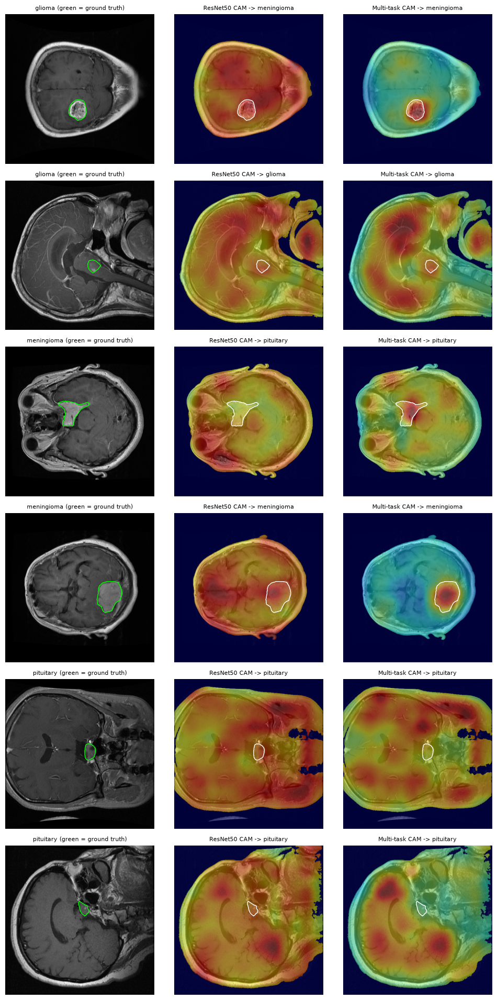

In [54]:
# Phase 10 — Cell 2: Heat-map gallery (2 test images per class) — MRI | ResNet50 CAM | multi-task CAM
rng = np.random.default_rng(3)
picks = []
for c in CLASS_NAMES:
    picks += list(rng.choice(test_df.index[test_df.class_name == c], 2, replace=False))

fig, ax = plt.subplots(len(picks), 3, figsize=(10, 3.2 * len(picks)))
for i, k in enumerate(picks):
    r = test_df.loc[k]; sid = r["sample_id"]
    img, gt, brain = load_case(r)
    ho = upsample(cams_old_test[sid]) * brain
    hn = upsample(cams_mt_test[sid]) * brain
    ax[i, 0].imshow(img[..., 0], cmap="gray"); ax[i, 0].contour(gt, levels=[0.5], colors="lime", linewidths=1)
    ax[i, 0].set_title(f"{r['class_name']} (green = ground truth)", fontsize=8)
    ax[i, 1].imshow(img[..., 0], cmap="gray"); ax[i, 1].imshow(ho, cmap="jet", alpha=0.45); ax[i, 1].contour(gt, levels=[0.5], colors="white", linewidths=1)
    ax[i, 1].set_title(f"ResNet50 CAM -> {CLASS_NAMES[info_old_test[sid]['pred']]}", fontsize=8)
    ax[i, 2].imshow(img[..., 0], cmap="gray"); ax[i, 2].imshow(hn, cmap="jet", alpha=0.45); ax[i, 2].contour(gt, levels=[0.5], colors="white", linewidths=1)
    ax[i, 2].set_title(f"Multi-task CAM -> {CLASS_NAMES[info_mt_test[sid]['pred']]}", fontsize=8)
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "phase10_heatmap_gallery.png", dpi=200); plt.show()

tune ResNet50:   0%|          | 0/491 [00:00<?, ?it/s]

tune multi-task:   0%|          | 0/491 [00:00<?, ?it/s]

ResNet50 CAM (classification-only)   chosen on validation: rel_max = 0.8   (val Dice 0.103, val bbox-IoU 0.075)
Multi-task CAM                       chosen on validation: top_pct = 5.0   (val Dice 0.293, val bbox-IoU 0.235)


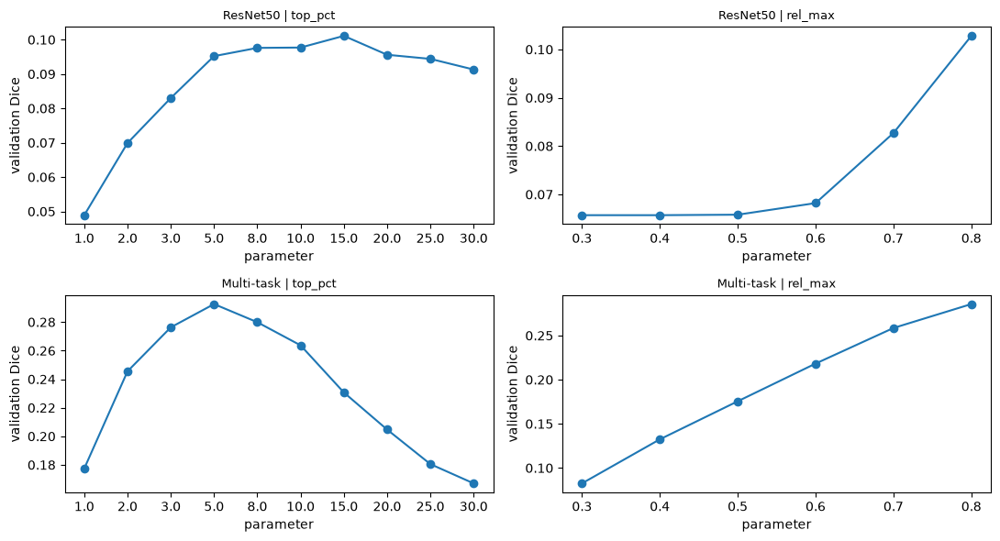

In [55]:
# Phase 11 — Cell 1: Choose the heat-map → region rule on VALIDATION
GRID_PCT = (1, 2, 3, 5, 8, 10, 15, 20, 25, 30)
GRID_REL = (0.3, 0.4, 0.5, 0.6, 0.7, 0.8)

def tune_region(df, cams, name):
    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc=f"tune {name}"):
        img, gt, brain = load_case(r)
        heat = upsample(cams[r["sample_id"]])
        for strat, grid in (("top_pct", GRID_PCT), ("rel_max", GRID_REL)):
            for p in grid:
                m = make_region(heat, brain, strat, p)
                rows.append(dict(strategy=strat, param=p, dice=dice(m, gt), bbox_iou=bbox_iou(bbox_of(m), bbox_of(gt))))
    t = pd.DataFrame(rows).groupby(["strategy", "param"])[["dice", "bbox_iou"]].mean().round(4)
    return t

tune_old = tune_region(val_df, cams_old_val, "ResNet50")
tune_mt  = tune_region(val_df, cams_mt_val,  "multi-task")
tune_old.to_csv(OUT_DIR / "region_tuning_resnet50_val.csv"); tune_mt.to_csv(OUT_DIR / "region_tuning_multitask_val.csv")

M_OLD = "ResNet50 CAM (classification-only)"
M_MT  = "Multi-task CAM"
M_SEG = "Multi-task segmentation head"
M_CTR = "Centre prior (baseline)"
M_RND = "Random smooth map (baseline)"

REGION_CFG = {}
for name, t in [(M_OLD, tune_old), (M_MT, tune_mt)]:
    strat, param = t["dice"].idxmax()
    REGION_CFG[name] = (strat, float(param))
    print(f"{name:36s} chosen on validation: {strat} = {param}   (val Dice {t['dice'].max():.3f}, val bbox-IoU {t.loc[(strat, param), 'bbox_iou']:.3f})")
REGION_CFG[M_SEG] = ("abs_thr", 0.4)
REGION_CFG[M_CTR] = REGION_CFG[M_MT]
REGION_CFG[M_RND] = REGION_CFG[M_MT]
json.dump({k: list(v) for k, v in REGION_CFG.items()}, open(OUT_DIR / "region_rules_chosen_on_validation.json", "w"), indent=1)

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for i, (name, t) in enumerate([("ResNet50", tune_old), ("Multi-task", tune_mt)]):
    for j, strat in enumerate(("top_pct", "rel_max")):
        s_ = t.loc[strat]["dice"]
        ax[i, j].plot([str(p) for p in s_.index], s_.values, marker="o")
        ax[i, j].set_title(f"{name} | {strat}", fontsize=9); ax[i, j].set_ylabel("validation Dice"); ax[i, j].set_xlabel("parameter")
plt.tight_layout(); plt.savefig(FIG_DIR / "phase11_region_rule_tuning.png", dpi=200); plt.show()

In [56]:
# Phase 12 — Cell 1: Score every image with every localizer
def evaluate_split(df, cams_old, cams_mt, seg_dict, info_old, info_mt, tag):
    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc=tag):
        sid = r["sample_id"]
        img, gt, brain = load_case(r)
        gt_dil = ndi.binary_dilation(gt, iterations=10)
        gcy, gcx = ndi.center_of_mass(gt); bcy, bcx = ndi.center_of_mass(brain)
        rng = np.random.default_rng(int(sid))

        yy, xx = np.mgrid[0:ORIG, 0:ORIG]
        diam = np.sqrt(4.0 * brain.sum() / np.pi)
        centre = np.exp(-((yy - bcy) ** 2 + (xx - bcx) ** 2) / (2 * (0.2 * diam) ** 2)).astype(np.float32)
        rnd = ndi.gaussian_filter(rng.random((ORIG, ORIG)).astype(np.float32), 25)
        rnd = (rnd - rnd.min()) / (rnd.max() - rnd.min() + 1e-8)

        heats = {M_OLD: upsample(cams_old[sid]), M_MT: upsample(cams_mt[sid]),
                 M_SEG: resize_prob(seg_dict[sid]), M_CTR: centre, M_RND: rnd}
        preds = {M_OLD: info_old[sid]["pred"], M_MT: info_mt[sid]["pred"], M_SEG: info_mt[sid]["pred"],
                 M_CTR: info_mt[sid]["pred"], M_RND: info_mt[sid]["pred"]}
        true_idx = CLASS_TO_INDEX[r["class_name"]]
        for method, heat in heats.items():
            strat, param = REGION_CFG[method]
            region = make_region(heat, brain, strat, param)
            rows.append(dict(sample_id=sid, patient_id=r["patient_id"], class_name=r["class_name"], method=method,
                             correct=bool(preds[method] == true_idx), tumor_pixels=int(r["tumor_pixels"]),
                             brain_frac=float(brain.mean()), mean_int=float(img[..., 0][brain].mean()),
                             gt_offset=float(np.hypot(gcy - bcy, gcx - bcx) / np.sqrt(brain.sum())),
                             **heat_metrics(heat, gt, gt_dil, brain, (gcy, gcx)), **region_metrics(region, gt)))
    return pd.DataFrame(rows)

val_eval = evaluate_split(val_df, cams_old_val, cams_mt_val, SEG_DICT_val, info_old_val, info_mt_val, "VAL scoring")
val_eval.to_csv(OUT_DIR / "localization_val_per_image.csv", index=False)
test_eval = evaluate_split(test_df, cams_old_test, cams_mt_test, SEG_DICT_test, info_old_test, info_mt_test, "TEST scoring")
test_eval.to_csv(OUT_DIR / "localization_test_per_image.csv", index=False)
print("Rows:", len(test_eval), "(= 489 images x 5 localizers)")

VAL scoring:   0%|          | 0/491 [00:00<?, ?it/s]

TEST scoring:   0%|          | 0/489 [00:00<?, ?it/s]

Rows: 2445 (= 489 images x 5 localizers)


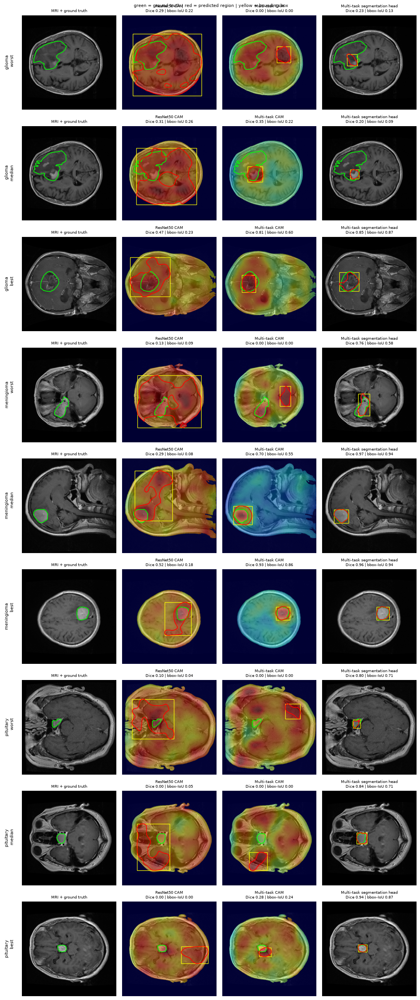

In [57]:
# Phase 12 — Cell 2: Qualitative comparison — best / median / worst case per class (ranked by multi-task CAM Dice)
def draw_case(axs, row):
    sid = row["sample_id"]
    img, gt, brain = load_case(row)
    items = [("MRI + ground truth", None, None),
             (M_OLD, upsample(cams_old_test[sid]) * brain, REGION_CFG[M_OLD]),
             (M_MT, upsample(cams_mt_test[sid]) * brain, REGION_CFG[M_MT]),
             (M_SEG, resize_prob(SEG_DICT_test[sid]), REGION_CFG[M_SEG])]
    for a, (title, heat, cfg) in zip(axs, items):
        a.imshow(img[..., 0], cmap="gray")
        a.contour(gt, levels=[0.5], colors="lime", linewidths=1.2)
        if heat is not None:
            if title != M_SEG:
                a.imshow(heat, cmap="jet", alpha=0.40)
            reg = make_region(heat, brain, *cfg)
            if reg.any():
                a.contour(reg, levels=[0.5], colors="red", linewidths=1.2)
                b = bbox_of(reg)
                a.add_patch(plt.Rectangle((b[1], b[0]), b[3] - b[1], b[2] - b[0], fill=False, edgecolor="yellow", linewidth=1))
            m = test_eval[(test_eval.sample_id == sid) & (test_eval.method == title)].iloc[0]
            title = f"{title.split('(')[0].strip()}\nDice {m['dice']:.2f} | bbox-IoU {m['bbox_iou']:.2f}"
        a.set_title(title, fontsize=7); a.axis("off")

mt_rows = test_eval[test_eval.method == M_MT].set_index("sample_id")
cases = []
for c in CLASS_NAMES:
    s = mt_rows[mt_rows.class_name == c].sort_values("dice")
    for tag, pos in [("worst", 0), ("median", len(s) // 2), ("best", len(s) - 1)]:
        cases.append((c, tag, s.index[pos]))

fig, ax = plt.subplots(len(cases), 4, figsize=(11, 2.9 * len(cases)))
for i, (c, tag, sid) in enumerate(cases):
    draw_case(ax[i], test_df[test_df.sample_id == sid].iloc[0])
    ax[i, 0].text(-0.08, 0.5, f"{c}\n{tag}", transform=ax[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
fig.text(0.5, 0.995, "green = ground truth | red = predicted region | yellow = bounding box", ha="center", va="top", fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "phase12_region_vs_groundtruth.png", dpi=200); plt.show()

,Pointing game,Energy in mask,Pixel AUC,Dice (top-5 %),Region Dice,Region IoU,BBox IoU,Hit@BBox-IoU>=0.5,Centroid dist (px)
ResNet50 CAM (classification-only),"0.198 [0.132, 0.268]","0.038 [0.028, 0.048]","0.654 [0.590, 0.716]","0.126 [0.085, 0.168]","0.113 [0.080, 0.145]","0.068 [0.047, 0.088]","0.073 [0.052, 0.093]","0.014 [0.000, 0.034]","100.714 [93.208, 111.776]"
Multi-task CAM,"0.460 [0.321, 0.613]","0.049 [0.035, 0.062]","0.719 [0.611, 0.820]","0.298 [0.199, 0.402]","0.290 [0.195, 0.392]","0.218 [0.146, 0.301]","0.231 [0.155, 0.314]","0.215 [0.121, 0.325]","77.769 [59.247, 95.170]"
Multi-task segmentation head,"0.935 [0.903, 0.966]","0.739 [0.684, 0.794]","0.979 [0.971, 0.987]","0.536 [0.469, 0.597]","0.738 [0.689, 0.789]","0.637 [0.582, 0.693]","0.644 [0.589, 0.699]","0.761 [0.676, 0.844]","14.406 [9.298, 19.423]"
Centre prior (baseline),"0.188 [0.126, 0.253]","0.061 [0.048, 0.075]","0.802 [0.738, 0.857]","0.128 [0.086, 0.173]","0.128 [0.086, 0.173]","0.077 [0.051, 0.105]","0.101 [0.072, 0.131]","0.004 [0.000, 0.013]","76.529 [64.612, 90.079]"
Random smooth map (baseline),"0.031 [0.015, 0.046]","0.035 [0.026, 0.045]","0.491 [0.469, 0.512]","0.032 [0.021, 0.043]","0.024 [0.015, 0.034]","0.015 [0.009, 0.022]","0.022 [0.014, 0.031]","0.006 [0.000, 0.016]","160.094 [152.600, 169.190]"


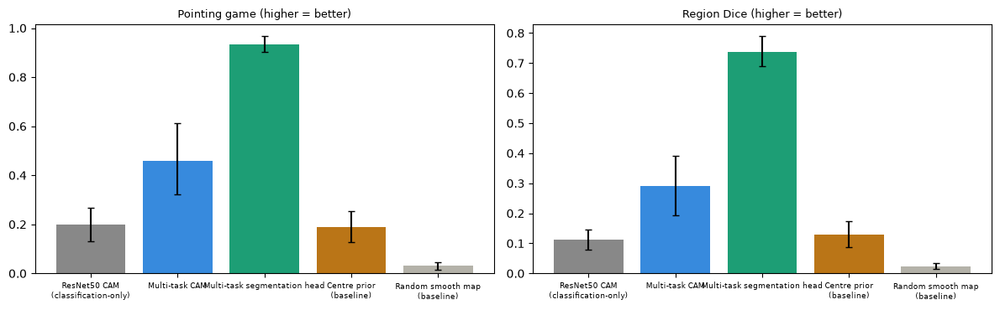

In [58]:
# Phase 13 — Cell 1: Headline localization table with 95 % CIs
METRICS = ["pointing_hit", "energy_in_mask", "pixel_auc", "dice_top5",
           "dice", "iou", "bbox_iou", "hit_bbox50", "centroid_dist"]
head = ci_table(test_eval, "method", METRICS)
head.columns = ["Pointing game", "Energy in mask", "Pixel AUC", "Dice (top-5 %)",
                "Region Dice", "Region IoU", "BBox IoU", "Hit@BBox-IoU>=0.5", "Centroid dist (px)"]
display(head)
head.to_csv(OUT_DIR / "table_localization_test_ci.csv")

# bar chart (mean +- CI) for two key metrics
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, col, ttl in [(ax[0], "pointing_hit", "Pointing game (higher = better)"), (ax[1], "dice", "Region Dice (higher = better)")]:
    stats = {m: patient_bootstrap(g, [col], n=1000).iloc[0] for m, g in test_eval.groupby("method", sort=False)}
    names = list(stats)
    mean = np.array([stats[n_]["mean"] for n_ in names])
    err = np.array([[stats[n_]["mean"] - stats[n_]["ci_low"] for n_ in names], [stats[n_]["ci_high"] - stats[n_]["mean"] for n_ in names]])
    a.bar(range(len(names)), mean, yerr=err, capsize=3, color=["#888", "#378ADD", "#1D9E75", "#BA7517", "#B4B2A9"])
    a.set_xticks(range(len(names))); a.set_xticklabels([n_.replace(" (", "\n(") for n_ in names], fontsize=6.5, rotation=0)
    a.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "phase13_localization_bars.png", dpi=200); plt.show()

In [59]:
# Phase 13 — Cell 2: Paired differences (same images, patient-level CI)
def paired_diff(frame, m_a, m_b, col, n=BOOT_N):
    a = frame[frame.method == m_a].set_index("sample_id"); b = frame[frame.method == m_b].set_index("sample_id")
    d = pd.DataFrame({"patient_id": a.patient_id, "d": a[col] - b.loc[a.index, col]}).reset_index()
    bm = boot_means(d, ["d"], n)[:, 0]
    return d["d"].mean(), np.percentile(bm, 2.5), np.percentile(bm, 97.5), float((bm > 0).mean())

rows = []
for col in ["pointing_hit", "dice", "bbox_iou", "pixel_auc"]:
    for a_, b_ in [(M_MT, M_OLD), (M_MT, M_CTR), (M_OLD, M_CTR), (M_SEG, M_MT)]:
        m, lo, hi, share = paired_diff(test_eval, a_, b_, col)
        rows.append(dict(metric=col, comparison=f"{a_.split('(')[0].strip()} - {b_.split('(')[0].strip()}",
                         mean_diff=round(m, 3), ci95=f"[{lo:+.3f}, {hi:+.3f}]", P_better=f"{share:.1%}"))
paired = pd.DataFrame(rows)
display(paired)
paired.to_csv(OUT_DIR / "table_localization_paired_differences.csv", index=False)
print("Reading guide: if the CI of 'CAM - Centre prior' includes 0, that CAM is not demonstrably better than a trivial centre-bias.")

,metric,comparison,mean_diff,ci95,P_better
0,pointing_hit,Multi-task CAM - ResNet50 CAM,0.262,"[+0.163, +0.375]",100.0%
1,pointing_hit,Multi-task CAM - Centre prior,0.272,"[+0.073, +0.463]",99.8%
2,pointing_hit,ResNet50 CAM - Centre prior,0.010,"[-0.105, +0.116]",56.4%
3,pointing_hit,Multi-task segmentation head - Multi-task CAM,0.474,"[+0.339, +0.608]",100.0%
4,dice,Multi-task CAM - ResNet50 CAM,0.176,"[+0.106, +0.257]",100.0%
5,dice,Multi-task CAM - Centre prior,0.162,"[+0.030, +0.286]",99.1%
6,dice,ResNet50 CAM - Centre prior,-0.015,"[-0.088, +0.050]",35.0%
7,dice,Multi-task segmentation head - Multi-task CAM,0.448,"[+0.356, +0.545]",100.0%
8,bbox_iou,Multi-task CAM - ResNet50 CAM,0.158,"[+0.097, +0.226]",100.0%
9,bbox_iou,Multi-task CAM - Centre prior,0.130,"[+0.031, +0.226]",99.6%


Reading guide: if the CI of 'CAM - Centre prior' includes 0, that CAM is not demonstrably better than a trivial centre-bias.


In [60]:
# Phase 13 — Cell 3: Where does localization work? by class / by correctness / by tumour size
mt_t = test_eval[test_eval.method == M_MT].copy()

print("=== By tumour class (every localizer) — pointing game ===")
display(test_eval.pivot_table(index="class_name", columns="method", values="pointing_hit", aggfunc="mean").round(3)[[M_OLD, M_MT, M_SEG, M_CTR, M_RND]])
print("=== By tumour class (every localizer) — region Dice ===")
display(test_eval.pivot_table(index="class_name", columns="method", values="dice", aggfunc="mean").round(3)[[M_OLD, M_MT, M_SEG, M_CTR, M_RND]])

print("=== Multi-task CAM: correctly vs wrongly classified ===")
display(mt_t.groupby("correct")[["pointing_hit", "dice", "bbox_iou", "pixel_auc"]].agg(["count", "mean"]).round(3))

mt_t["size_group"] = pd.qcut(mt_t.tumor_pixels, 3, labels=["small", "medium", "large"])
print("=== Multi-task CAM by tumour size tertile ===")
display(mt_t.groupby("size_group", observed=True)[["tumor_pixels", "pointing_hit", "dice", "bbox_iou"]].mean().round(3))
rho, p = spearmanr(mt_t.tumor_pixels, mt_t.dice)
print(f"Spearman(tumour size, region Dice) = {rho:.3f} (p = {p:.3g})")

=== By tumour class (every localizer) — pointing game ===


method,ResNet50 CAM (classification-only),Multi-task CAM,Multi-task segmentation head,Centre prior (baseline),Random smooth map (baseline)
class_name,,,,,
glioma,0.196,0.536,0.884,0.134,0.045
meningioma,0.388,0.871,1.000,0.121,0.026
pituitary,0.054,0.027,0.960,0.322,0.013


=== By tumour class (every localizer) — region Dice ===


method,ResNet50 CAM (classification-only),Multi-task CAM,Multi-task segmentation head,Centre prior (baseline),Random smooth map (baseline)
class_name,,,,,
glioma,0.138,0.321,0.632,0.067,0.036
meningioma,0.181,0.599,0.897,0.097,0.020
pituitary,0.023,0.002,0.774,0.245,0.008


=== Multi-task CAM: correctly vs wrongly classified ===


pointing_hit         dice        bbox_iou        pixel_auc       
               count   mean count   mean    count   mean     count   mean
correct                                                                  
False             45  0.467    45  0.275       45  0.208        45  0.807
True             444  0.459   444  0.291      444  0.233       444  0.710

=== Multi-task CAM by tumour size tertile ===


,tumor_pixels,pointing_hit,dice,bbox_iou
size_group,,,,
small,1321.840,0.166,0.065,0.045
medium,3303.969,0.503,0.315,0.255
large,8668.693,0.712,0.489,0.392


Spearman(tumour size, region Dice) = 0.550 (p = 4.59e-40)


Pituitary test images: 149


,pointing_hit,pixel_auc,dice,peak_dist,median_peak_dist_px
method,,,,,
ResNet50 CAM (classification-only),0.054,0.460,0.023,164.930,158.0
Multi-task CAM,0.027,0.337,0.002,129.991,130.4
Multi-task segmentation head,0.960,0.988,0.774,14.221,10.9
Centre prior (baseline),0.322,0.967,0.245,38.485,40.6
Random smooth map (baseline),0.013,0.485,0.008,192.698,197.7


Mean offset of the pituitary tumour from the brain centre (fraction of brain diameter): 0.094
Mean offset for glioma / meningioma: 0.271 / 0.254


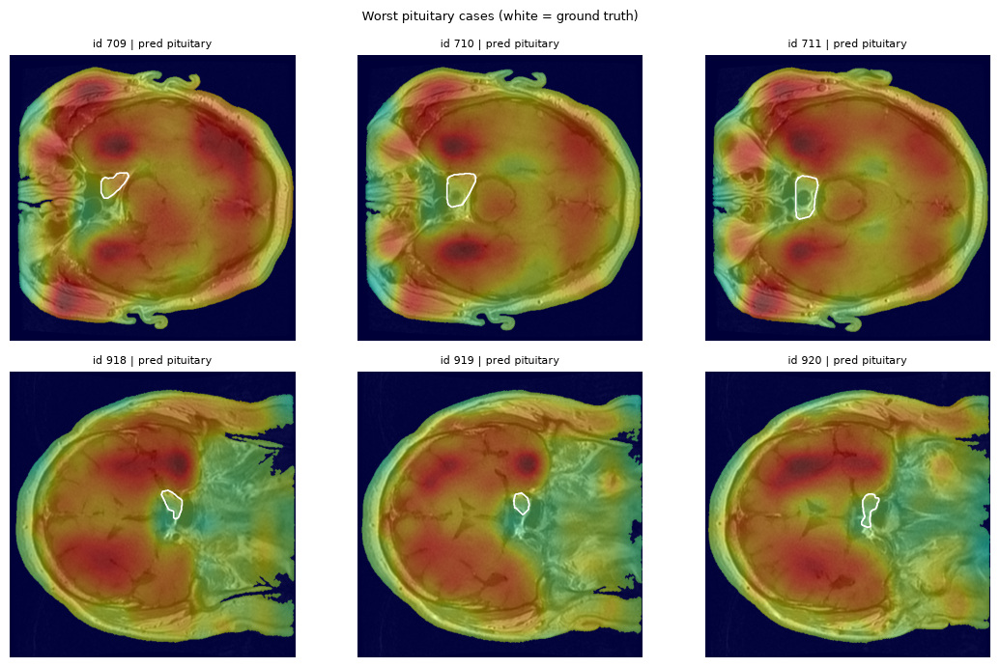

In [61]:
# Phase 13 — Cell 4: Diagnose the weakest class (pituitary) — is the CAM pointing at the wrong place, or just at the centre?
pit = test_eval[(test_eval.class_name == "pituitary")]
tab = pit.groupby("method", sort=False)[["pointing_hit", "pixel_auc", "dice", "peak_dist"]].mean().round(3)
tab["median_peak_dist_px"] = pit.groupby("method", sort=False)["peak_dist"].median().round(1)
print("Pituitary test images:", pit.sample_id.nunique())
display(tab)
print("Mean offset of the pituitary tumour from the brain centre (fraction of brain diameter):",
      round(float(pit[pit.method == M_MT].gt_offset.mean()), 3))
print("Mean offset for glioma / meningioma:",
      round(float(test_eval[(test_eval.method == M_MT) & (test_eval.class_name == 'glioma')].gt_offset.mean()), 3), "/",
      round(float(test_eval[(test_eval.method == M_MT) & (test_eval.class_name == 'meningioma')].gt_offset.mean()), 3))

# 6 worst pituitary cases for the multi-task CAM
worst = pit[pit.method == M_MT].nsmallest(6, "dice").sample_id.tolist()
fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for a, sid in zip(ax.flat, worst):
    r = test_df[test_df.sample_id == sid].iloc[0]
    img, gt, brain = load_case(r)
    a.imshow(img[..., 0], cmap="gray"); a.imshow(upsample(cams_mt_test[sid]) * brain, cmap="jet", alpha=0.45)
    a.contour(gt, levels=[0.5], colors="white", linewidths=1.2)
    a.set_title(f"id {sid} | pred {CLASS_NAMES[info_mt_test[sid]['pred']]}", fontsize=8); a.axis("off")
plt.suptitle("Worst pituitary cases (white = ground truth)", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "phase13_pituitary_failures.png", dpi=200); plt.show()

In [62]:
# Phase 13 — Cell 5: Import the faithfulness (tumour-ablation) results already computed in XAI_Fix_Notebook
ab_files = {"ResNet50 (classification-only)": V2_DIR / "ablation_resnet50.csv", "Multi-task": V2_DIR / "ablation_multitask.csv"}
ab = {}
for name, f in ab_files.items():
    if f.exists():
        ab[name] = pd.read_csv(f)
if len(ab) == 2:
    a_, b_ = list(ab.values())
    net_a, net_b = a_.drop_tumour - a_.drop_control, b_.drop_tumour - b_.drop_control
    faith = pd.DataFrame({
        "n": [len(a_), len(b_)],
        "prob drop (tumour removed)": [a_.drop_tumour.mean(), b_.drop_tumour.mean()],
        "prob drop (control patch)": [a_.drop_control.mean(), b_.drop_control.mean()],
        "net tumour effect": [net_a.mean(), net_b.mean()],
        "prediction flips (tumour removed)": [a_.flip_tumour.mean(), b_.flip_tumour.mean()]},
        index=list(ab)).round(3)
    display(faith)
    print("Paired Wilcoxon, multi-task vs ResNet50 net effect: p =", round(float(wilcoxon(net_b, net_a).pvalue), 4))
    faith.to_csv(OUT_DIR / "table_faithfulness_ablation.csv")
else:
    print("Ablation CSVs not found in", V2_DIR, "- skip (they are written by XAI_Fix_Notebook, section 5).")

,n,prob drop (tumour removed),prob drop (control patch),net tumour effect,prediction flips (tumour removed)
ResNet50 (classification-only),149,0.055,0.010,0.045,0.060
Multi-task,149,0.124,0.005,0.119,0.148


Paired Wilcoxon, multi-task vs ResNet50 net effect: p = 0.1913


11 perturbations + clean reference


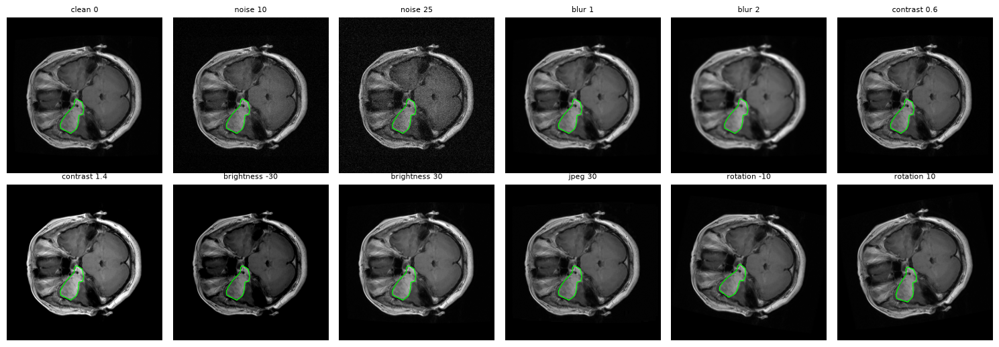

In [63]:
# Phase 14 — Cell 1: Perturbation definitions
def f_clean(im, gt, rng): return im, gt

def f_noise(sigma):
    def f(im, gt, rng):
        n = rng.normal(0, sigma, im.shape[:2])[..., None]
        return np.clip(im.astype(np.float32) + n, 0, 255).astype(np.uint8), gt
    return f

def f_blur(sigma):
    def f(im, gt, rng):
        return np.clip(ndi.gaussian_filter(im.astype(np.float32), sigma=(sigma, sigma, 0)), 0, 255).astype(np.uint8), gt
    return f

def f_contrast(factor):
    def f(im, gt, rng):
        x = im.astype(np.float32); m = x.mean()
        return np.clip((x - m) * factor + m, 0, 255).astype(np.uint8), gt
    return f

def f_brightness(delta):
    def f(im, gt, rng):
        return np.clip(im.astype(np.float32) + delta, 0, 255).astype(np.uint8), gt
    return f

def f_jpeg(quality):
    def f(im, gt, rng):
        buf = io.BytesIO(); Image.fromarray(im).save(buf, format="JPEG", quality=quality); buf.seek(0)
        return np.array(Image.open(buf).convert("RGB")), gt
    return f

def f_rotate(deg):
    def f(im, gt, rng):
        im2 = ndi.rotate(im, deg, axes=(1, 0), reshape=False, order=1, mode="constant", cval=0).astype(np.uint8)
        gt2 = ndi.rotate(gt.astype(np.uint8), deg, axes=(1, 0), reshape=False, order=0, mode="constant", cval=0) > 0
        return im2, gt2
    return f

CONDITIONS = [("clean", 0, f_clean),
              ("noise", 10, f_noise(10)), ("noise", 25, f_noise(25)),
              ("blur", 1, f_blur(1)), ("blur", 2, f_blur(2)),
              ("contrast", 0.6, f_contrast(0.6)), ("contrast", 1.4, f_contrast(1.4)),
              ("brightness", -30, f_brightness(-30)), ("brightness", 30, f_brightness(30)),
              ("jpeg", 30, f_jpeg(30)),
              ("rotation", -10, f_rotate(-10)), ("rotation", 10, f_rotate(10))]
CLEAN_X = {"noise": 0, "blur": 0, "contrast": 1.0, "brightness": 0, "jpeg": 100, "rotation": 0}
print(len(CONDITIONS) - 1, "perturbations +", "clean reference")

# quick visual check of the perturbations on one image
r0 = test_df.iloc[0]; img0, gt0 = read_case_raw(r0)
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for a, (fam, lvl, fn) in zip(ax.flat, CONDITIONS):
    im_p, gt_p = fn(img0, gt0, np.random.default_rng(0))
    a.imshow(im_p[..., 0], cmap="gray"); a.contour(gt_p, levels=[0.5], colors="lime", linewidths=0.8)
    a.set_title(f"{fam} {lvl}", fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "phase14_perturbation_examples.png", dpi=150); plt.show()

In [64]:
# Phase 14 — Cell 2: Run the robustness study (cached to CSV; delete the CSV to re-run)
ROB_PATH = OUT_DIR / "robustness_per_image.csv"

def run_robustness(df, n):
    sub = df.sample(n, random_state=0).reset_index(drop=True) if n else df
    rows, clean_cam = [], {M_OLD: {}, M_MT: {}}
    for fam, lvl, fn in CONDITIONS:
        for _, r in tqdm(sub.iterrows(), total=len(sub), desc=f"{fam} {lvl}"):
            sid = r["sample_id"]
            img0, gt0 = read_case_raw(r)
            img, gt = fn(img0, gt0, np.random.default_rng(int(sid) + 17))
            brain = brain_mask(img); gt_dil = ndi.binary_dilation(gt, iterations=10)
            x = prep_resnet(img)
            true_idx = CLASS_TO_INDEX[r["class_name"]]

            seg_p = resize_prob(mt.predict(x, verbose=0)[1][0, ..., 0])
            seg_d = dice(make_region(seg_p, brain, *REGION_CFG[M_SEG]), gt)

            for name, expl in ((M_OLD, expl_old), (M_MT, expl_mt)):
                maps, cidx, probs = expl(x)
                cam = maps[LAYER][METHOD]
                heat = upsample(cam) * brain
                py, px = np.unravel_index(np.argmax(heat), heat.shape)
                region = make_region(heat, brain, *REGION_CFG[name])
                if fam == "clean":
                    clean_cam[name][sid] = cam; stab = 1.0
                elif fam == "rotation":
                    stab = np.nan
                else:
                    c0 = clean_cam[name][sid]
                    stab = float(np.corrcoef(c0.ravel(), cam.ravel())[0, 1]) if c0.std() > 0 and cam.std() > 0 else np.nan
                rows.append(dict(model=name, family=fam, level=lvl, sample_id=sid, patient_id=r["patient_id"],
                                 class_name=r["class_name"], true_idx=true_idx, pred_idx=int(cidx),
                                 correct=bool(cidx == true_idx), pointing_hit=float(gt_dil[py, px]),
                                 dice_region=dice(region, gt), stability=stab,
                                 seg_dice=seg_d if name == M_MT else np.nan))
    return pd.DataFrame(rows)

if ROB_PATH.exists():
    rob = pd.read_csv(ROB_PATH, dtype={"sample_id": str, "patient_id": str})
    print("Loaded cached robustness results:", len(rob), "rows")
else:
    t0 = time.time()
    rob = run_robustness(test_df, ROBUST_N)
    rob.to_csv(ROB_PATH, index=False)
    print(f"Robustness study finished in {(time.time() - t0) / 60:.1f} min -> {ROB_PATH.name}")

Loaded cached robustness results: 2880 rows


Clean reference on the robustness subset:


,n,accuracy,macro_f1,pointing_hit,dice_region,seg_dice
model,,,,,,
ResNet50 CAM (classification-only),120.0,0.883,0.868,0.192,0.119,NaN
Multi-task CAM,120.0,0.917,0.909,0.467,0.295,0.766



Change vs clean (positive drop = worse):


,model,family,level,accuracy,accuracy_drop,pointing_hit,pointing_hit_drop,dice_region,dice_region_drop,stability
0,ResNet50 CAM (classification-only),noise,10.0,0.742,0.142,0.175,0.017,0.109,0.010,0.825
1,Multi-task CAM,noise,10.0,0.792,0.125,0.492,-0.025,0.303,-0.008,0.907
2,ResNet50 CAM (classification-only),noise,25.0,0.633,0.250,0.133,0.058,0.083,0.036,0.731
3,Multi-task CAM,noise,25.0,0.783,0.133,0.475,-0.008,0.312,-0.017,0.854
4,ResNet50 CAM (classification-only),blur,1.0,0.875,0.008,0.125,0.067,0.109,0.010,0.972
5,Multi-task CAM,blur,1.0,0.917,0.000,0.458,0.008,0.294,0.001,0.989
6,ResNet50 CAM (classification-only),blur,2.0,0.825,0.058,0.167,0.025,0.103,0.016,0.897
7,Multi-task CAM,blur,2.0,0.908,0.008,0.458,0.008,0.297,-0.002,0.963
8,ResNet50 CAM (classification-only),contrast,0.6,0.825,0.058,0.142,0.050,0.092,0.027,0.911
9,Multi-task CAM,contrast,0.6,0.908,0.008,0.458,0.008,0.271,0.024,0.953


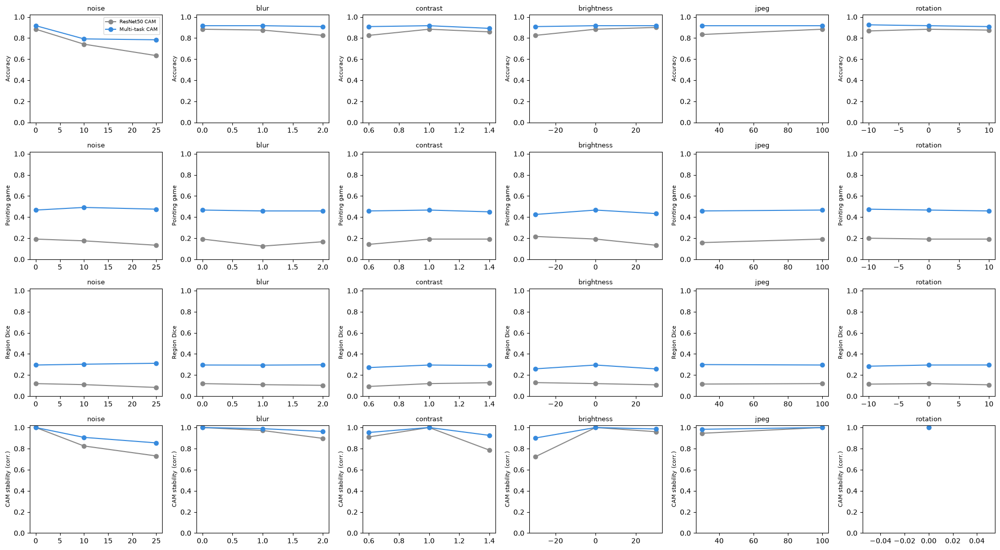

In [65]:
# Phase 14 — Cell 3: Robustness summary table and curves
def summarise(g):
    return pd.Series(dict(n=len(g), accuracy=g.correct.mean(), macro_f1=f1_score(g.true_idx, g.pred_idx, average="macro"),
                          pointing_hit=g.pointing_hit.mean(), dice_region=g.dice_region.mean(),
                          stability=g.stability.mean(), seg_dice=g.seg_dice.mean()))

rob_sum = pd.DataFrame([dict(model=m, family=f, level=l, **summarise(g))
                        for (m, f, l), g in rob.groupby(["model", "family", "level"], sort=False)])
rob_sum.to_csv(OUT_DIR / "table_robustness_summary.csv", index=False)

clean = rob_sum[rob_sum.family == "clean"].set_index("model")
rel = rob_sum[rob_sum.family != "clean"].copy()
for col in ["accuracy", "pointing_hit", "dice_region"]:
    rel[f"{col}_drop"] = rel.apply(lambda r: clean.loc[r["model"], col] - r[col], axis=1)
print("Clean reference on the robustness subset:")
display(clean[["n", "accuracy", "macro_f1", "pointing_hit", "dice_region", "seg_dice"]].round(3))
print("\nChange vs clean (positive drop = worse):")
display(rel[["model", "family", "level", "accuracy", "accuracy_drop", "pointing_hit", "pointing_hit_drop", "dice_region", "dice_region_drop", "stability"]]
        .round(3).reset_index(drop=True))
fams = ["noise", "blur", "contrast", "brightness", "jpeg", "rotation"]
mets = [("accuracy", "Accuracy"), ("pointing_hit", "Pointing game"), ("dice_region", "Region Dice"), ("stability", "CAM stability (corr.)")]
fig, ax = plt.subplots(len(mets), len(fams), figsize=(20, 11))
for i, (met, label) in enumerate(mets):
    for j, fam in enumerate(fams):
        for model, colr in [(M_OLD, "#888"), (M_MT, "#378ADD")]:
            s = rob_sum[(rob_sum.model == model) & (rob_sum.family == fam)][["level", met]].values.tolist()
            c0 = clean.loc[model, met] if met != "stability" else 1.0
            pts = sorted([(CLEAN_X[fam], c0)] + [tuple(p) for p in s])
            ax[i, j].plot([p[0] for p in pts], [p[1] for p in pts], marker="o", color=colr, label=model.split("(")[0].strip())
        ax[i, j].set_title(f"{fam}", fontsize=9); ax[i, j].set_ylabel(label, fontsize=8); ax[i, j].set_ylim(0, 1.02)
ax[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "phase14_robustness_curves.png", dpi=200); plt.show()

In [66]:
# Phase 15 — Cell 1: Validation -> test generalization gap
def macro_f1(P, y): return float(f1_score(y, P.argmax(1), average="macro"))
gap_cls = pd.DataFrame({
    "val_acc":  [acc(P_eff_val, y_val), acc(P_res_val, y_val), acc(P_mt_val, y_val)],
    "test_acc": [acc(P_eff_test, y_test), acc(P_res_test, y_test), acc(P_mt_test, y_test)],
    "val_macroF1":  [macro_f1(P_eff_val, y_val), macro_f1(P_res_val, y_val), macro_f1(P_mt_val, y_val)],
    "test_macroF1": [macro_f1(P_eff_test, y_test), macro_f1(P_res_test, y_test), macro_f1(P_mt_test, y_test)]},
    index=["EfficientNetB0", "ResNet50", "ResNet50-UNet multi-task"])
gap_cls["acc_gap (val-test)"] = gap_cls.val_acc - gap_cls.test_acc
print("=== Classification ===")
display(gap_cls.round(4))

cols = ["pointing_hit", "dice", "bbox_iou", "pixel_auc"]
g_loc = pd.concat({"val": val_eval.groupby("method", sort=False)[cols].mean(),
                   "test": test_eval.groupby("method", sort=False)[cols].mean()}, axis=1).round(3)
print("\n=== Localization (validation vs test) ===")
display(g_loc)
gap_cls.to_csv(OUT_DIR / "table_generalization_gap_classification.csv"); g_loc.to_csv(OUT_DIR / "table_generalization_gap_localization.csv")

=== Classification ===


,val_acc,test_acc,val_macroF1,test_macroF1,acc_gap (val-test)
EfficientNetB0,0.8798,0.8466,0.8730,0.8268,0.0332
ResNet50,0.9328,0.8528,0.9254,0.8428,0.0800
ResNet50-UNet multi-task,0.9532,0.9100,0.9491,0.9027,0.0431



=== Localization (validation vs test) ===


val                            \
                                   pointing_hit   dice bbox_iou pixel_auc   
method                                                                      
ResNet50 CAM (classification-only)        0.159  0.103    0.075     0.608   
Multi-task CAM                            0.483  0.293    0.235     0.750   
Multi-task segmentation head              0.912  0.749    0.663     0.980   
Centre prior (baseline)                   0.161  0.111    0.088     0.765   
Random smooth map (baseline)              0.045  0.028    0.025     0.504   

                                           test                            
                                   pointing_hit   dice bbox_iou pixel_auc  
method                                                                     
ResNet50 CAM (classification-only)        0.198  0.113    0.073     0.654  
Multi-task CAM                            0.460  0.290    0.231     0.719  
Multi-task segmentation head              0.935  0.738    0.644     0.979  
Centre prior (baseline)                   0.188  0.128    0.101     0.802  
Random smooth map (baseline)              0.031  0.024    0.022     0.491

In [67]:
# Phase 15 — Cell 2: Sub-group generalization inside the test set
eff_saved = pd.read_csv(CLS_DIR / "efficientnetb0_test_predictions.csv", dtype={"sample_id": str, "patient_id": str}).set_index("sample_id")
res_saved = pd.read_csv(CLS_DIR / "resnet50_test_predictions.csv", dtype={"sample_id": str, "patient_id": str}).set_index("sample_id")

sub = test_df[["sample_id", "patient_id", "class_name", "tumor_pixels"]].copy()
sub["true_idx"] = y_test
sub["EfficientNetB0"] = (eff_saved.loc[sub.sample_id, "predicted_index"].values == y_test)
sub["ResNet50"]       = (res_saved.loc[sub.sample_id, "predicted_index"].values == y_test)
sub["Multi-task"]     = (P_mt_test.argmax(1) == y_test)
sub["size_group"] = pd.qcut(sub.tumor_pixels, 3, labels=["small", "medium", "large"])
bright = test_eval[test_eval.method == M_MT].set_index("sample_id").mean_int
sub["brightness_group"] = pd.qcut(bright.loc[sub.sample_id].values, 3, labels=["dark", "medium", "bright"])

mods = ["EfficientNetB0", "ResNet50", "Multi-task"]
print("Sanity: accuracies recomputed from saved CSVs ->", {m: round(float(sub[m].mean()), 4) for m in mods})
for grp in ["class_name", "size_group", "brightness_group"]:
    t = sub.groupby(grp, observed=True)[mods].mean().round(3)
    t.insert(0, "n_images", sub.groupby(grp, observed=True).size())
    t.insert(1, "n_patients", sub.groupby(grp, observed=True).patient_id.nunique())
    print(f"\n=== Classification accuracy by {grp} ===")
    display(t)
    t.to_csv(OUT_DIR / f"table_generalization_subgroup_{grp}.csv")

mt_t = test_eval[test_eval.method == M_MT].copy()
mt_t["size_group"] = pd.qcut(mt_t.tumor_pixels, 3, labels=["small", "medium", "large"])
mt_t["brightness_group"] = pd.qcut(mt_t.mean_int, 3, labels=["dark", "medium", "bright"])
for grp in ["size_group", "brightness_group"]:
    print(f"\n=== Multi-task localization by {grp} ===")
    display(mt_t.groupby(grp, observed=True)[["pointing_hit", "dice", "bbox_iou"]].mean().round(3))

Sanity: accuracies recomputed from saved CSVs -> {'EfficientNetB0': 0.8466, 'ResNet50': 0.8528, 'Multi-task': 0.91}

=== Classification accuracy by class_name ===


,n_images,n_patients,EfficientNetB0,ResNet50,Multi-task
class_name,,,,,
glioma,224,14,0.879,0.835,0.933
meningioma,116,12,0.647,0.802,0.853
pituitary,149,9,0.953,0.919,0.919



=== Classification accuracy by size_group ===


,n_images,n_patients,EfficientNetB0,ResNet50,Multi-task
size_group,,,,,
small,163,29,0.865,0.847,0.871
medium,163,31,0.859,0.877,0.914
large,163,19,0.816,0.834,0.945



=== Classification accuracy by brightness_group ===


,n_images,n_patients,EfficientNetB0,ResNet50,Multi-task
brightness_group,,,,,
dark,163,26,0.896,0.902,0.908
medium,163,31,0.865,0.840,0.933
bright,163,28,0.779,0.816,0.890



=== Multi-task localization by size_group ===


,pointing_hit,dice,bbox_iou
size_group,,,
small,0.166,0.065,0.045
medium,0.503,0.315,0.255
large,0.712,0.489,0.392



=== Multi-task localization by brightness_group ===


,pointing_hit,dice,bbox_iou
brightness_group,,,
dark,0.423,0.246,0.192
medium,0.436,0.283,0.229
bright,0.521,0.341,0.272


Per-patient accuracy: mean / worst / patients below 70 %


,EfficientNetB0,ResNet50,Multi-task
mean,0.783,0.811,0.854
worst,0.000,0.000,0.000
patients < 70 %,10.000,7.000,6.000



Worst 8 patients for the multi-task model:


,EfficientNetB0,ResNet50,Multi-task,n_images,class
patient_id,,,,,
110116,0.000,0.000,0.000,5,meningioma
95969,0.000,0.000,0.000,1,meningioma
102929,0.250,0.250,0.125,8,meningioma
102648,0.647,0.588,0.353,17,pituitary
100820,0.176,0.059,0.471,17,glioma
92897,0.250,0.500,0.500,4,glioma
101127,0.667,0.750,0.750,12,meningioma
101020,0.722,0.333,0.778,18,glioma


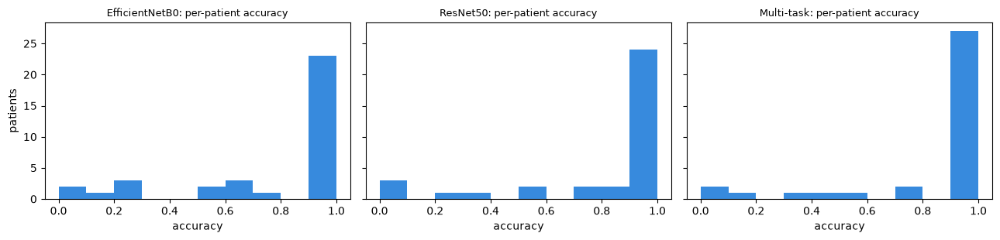

In [68]:
# Phase 15 — Cell 3: Patient-level spread (35 test patients)
pp = sub.groupby("patient_id")[mods].mean()
pp["n_images"] = sub.groupby("patient_id").size()
pp["class"] = sub.groupby("patient_id").class_name.first()
print("Per-patient accuracy: mean / worst / patients below 70 %")
display(pd.DataFrame({m: [pp[m].mean(), pp[m].min(), int((pp[m] < 0.70).sum())] for m in mods}, index=["mean", "worst", "patients < 70 %"]).round(3))
print("\nWorst 8 patients for the multi-task model:")
display(pp.sort_values("Multi-task").head(8).round(3))
pp.to_csv(OUT_DIR / "table_generalization_per_patient.csv")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a, m in zip(ax, mods):
    a.hist(pp[m], bins=10, range=(0, 1), color="#378ADD"); a.set_title(f"{m}: per-patient accuracy", fontsize=9); a.set_xlabel("accuracy")
ax[0].set_ylabel("patients")
plt.tight_layout(); plt.savefig(FIG_DIR / "phase15_patient_spread.png", dpi=200); plt.show()

In [69]:
# Phase 15 — Cell 4 (OPTIONAL): external-dataset test — the only real domain-shift check
# Put an independent brain-MRI classification dataset on disk with one sub-folder per class whose name contains
# "glioma", "meningioma" or "pituitary" (e.g. a public Kaggle brain-tumour set), then set EXTERNAL_DIR and run.
# Folders such as "notumor" are skipped. Images are min-max scaled exactly like your training PNGs.
EXTERNAL_DIR = None      # e.g. Path(r"C:\Users\lokes\Documents\external_brain_mri")

def collect_external(folder):
    items = []
    for d in sorted(Path(folder).iterdir()):
        if not d.is_dir():
            continue
        key = next((c for c in CLASS_NAMES if c in d.name.lower()), None)
        if key is None:
            print("Skipping folder:", d.name); continue
        for p in d.rglob("*"):
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
                items.append((str(p), CLASS_TO_INDEX[key]))
    return pd.DataFrame(items, columns=["image_path", "label"])

def load_external(path):
    a = np.array(Image.open(path).convert("L")).astype(np.float32)
    a = (a - a.min()) / (a.max() - a.min() + 1e-8) * 255.0
    return np.stack([a] * 3, axis=-1).astype(np.uint8)

if EXTERNAL_DIR is None:
    print("EXTERNAL_DIR not set -> external test skipped (state this as a limitation in the report).")
else:
    ext = collect_external(EXTERNAL_DIR)
    print("External images:", len(ext), "\n", ext.label.map(lambda i: CLASS_NAMES[i]).value_counts().to_dict())
    Pe = {"EfficientNetB0": [], "ResNet50": [], "Multi-task": []}
    for s in tqdm(range(0, len(ext), 16), desc="external"):
        imgs = [load_external(p) for p in ext.image_path.iloc[s:s + 16]]
        Xr = np.concatenate([prep_resnet(i) for i in imgs]); Xe = np.concatenate([prep_effnet(i) for i in imgs])
        Pe["EfficientNetB0"].append(effnet.predict(Xe, verbose=0)); Pe["ResNet50"].append(resnet.predict(Xr, verbose=0))
        Pe["Multi-task"].append(mt.predict(Xr, verbose=0)[0])
    ye = ext.label.to_numpy(); ext_rows = []
    for m in Pe:
        P = np.concatenate(Pe[m])
        ext_rows.append(dict(model=m, ext_acc=acc(P, ye), ext_macroF1=macro_f1(P, ye),
                             internal_test_acc=float(gap_cls.loc[{"Multi-task": "ResNet50-UNet multi-task"}.get(m, m), "test_acc"])))
        print(f"\n{m}\n", pd.DataFrame(confusion_matrix(ye, P.argmax(1), labels=[0, 1, 2]), index=CLASS_NAMES, columns=CLASS_NAMES))
    ext_tab = pd.DataFrame(ext_rows).round(4); display(ext_tab)
    ext_tab.to_csv(OUT_DIR / "table_external_validation.csv", index=False)

EXTERNAL_DIR not set -> external test skipped (state this as a limitation in the report).


,accuracy,ci_low,ci_high,macro_F1
model,,,,
EfficientNetB0,0.8466,0.7456,0.9239,0.8268
ResNet50,0.8528,0.7575,0.9258,0.8428
Multi-task,0.9100,0.8305,0.9674,0.9027


    Multi-task - ResNet50        accuracy difference +0.0573  95% CI [+0.012, +0.107]  P(better) 99.5%
      ResNet50 - EfficientNetB0  accuracy difference +0.0061  95% CI [-0.045, +0.066]  P(better) 58.5%
    Multi-task - EfficientNetB0  accuracy difference +0.0634  95% CI [+0.010, +0.135]  P(better) 99.0%


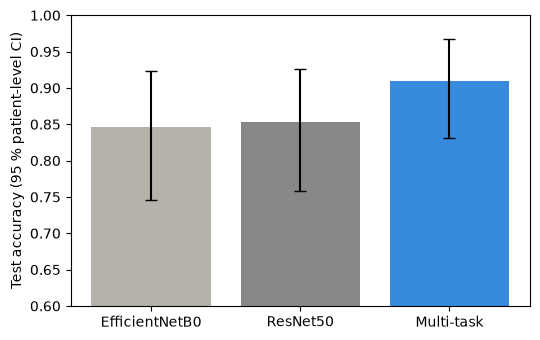

In [70]:
# Phase 16 — Cell 1: Classification comparison with patient-level 95 % CIs (+ paired test)
cls_frame = sub[["sample_id", "patient_id"]].copy()
for m in mods: cls_frame[m] = sub[m].astype(float).values
cls_rows = []
for m, P in [("EfficientNetB0", None), ("ResNet50", None), ("Multi-task", P_mt_test)]:
    t = patient_bootstrap(cls_frame, [m], n=BOOT_N).iloc[0]
    pred = (eff_saved.loc[sub.sample_id, "predicted_index"].values if m == "EfficientNetB0"
            else res_saved.loc[sub.sample_id, "predicted_index"].values if m == "ResNet50" else P_mt_test.argmax(1))
    cls_rows.append(dict(model=m, accuracy=t["mean"], ci_low=t["ci_low"], ci_high=t["ci_high"],
                         macro_F1=float(f1_score(y_test, pred, average="macro"))))
cls_tab = pd.DataFrame(cls_rows).set_index("model").round(4)
display(cls_tab); cls_tab.to_csv(OUT_DIR / "table_classification_final_ci.csv")

for a_, b_ in [("Multi-task", "ResNet50"), ("ResNet50", "EfficientNetB0"), ("Multi-task", "EfficientNetB0")]:
    d = cls_frame[["patient_id"]].copy(); d["d"] = cls_frame[a_] - cls_frame[b_]
    bm = boot_means(d, ["d"], BOOT_N)[:, 0]
    print(f"{a_:>14s} - {b_:<15s} accuracy difference {d.d.mean():+.4f}  95% CI [{np.percentile(bm, 2.5):+.3f}, {np.percentile(bm, 97.5):+.3f}]  P(better) {np.mean(bm > 0):.1%}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
err = np.array([cls_tab.accuracy - cls_tab.ci_low, cls_tab.ci_high - cls_tab.accuracy])
ax.bar(cls_tab.index, cls_tab.accuracy, yerr=err, capsize=4, color=["#B4B2A9", "#888", "#378ADD"])
ax.set_ylim(0.6, 1.0); ax.set_ylabel("Test accuracy (95 % patient-level CI)")
plt.tight_layout(); plt.savefig(FIG_DIR / "phase16_classification_ci.png", dpi=200); plt.show()

In [71]:
# Phase 16 — Cell 2: Auto-generated findings (verify each sentence against the tables before copying into the dissertation)
def g(method, col): return float(test_eval[test_eval.method == method][col].mean())
def cls_of(method, c, col): return float(test_eval[(test_eval.method == method) & (test_eval.class_name == c)][col].mean())
clean_mt = rob_sum[(rob_sum.family == "clean") & (rob_sum.model == M_MT)].iloc[0]
worst_acc = rel[rel.model == M_MT].sort_values("accuracy_drop", ascending=False).iloc[0]
worst_stab = rel[(rel.model == M_MT) & rel.stability.notna()].sort_values("stability").iloc[0]
_, ci_lo, ci_hi, _ = paired_diff(test_eval, M_MT, M_CTR, "pointing_hit")

findings = [
 f"1. CLASSIFICATION - EfficientNetB0 {cls_tab.loc['EfficientNetB0','accuracy']:.1%}, ResNet50 {cls_tab.loc['ResNet50','accuracy']:.1%}, multi-task {cls_tab.loc['Multi-task','accuracy']:.1%} test accuracy (patient-level 95% CI of the multi-task model: [{cls_tab.loc['Multi-task','ci_low']:.1%}, {cls_tab.loc['Multi-task','ci_high']:.1%}]).",
 f"2. LOCALIZATION (heat-map) - pointing game {g(M_OLD,'pointing_hit'):.1%} (ResNet50 CAM) vs {g(M_MT,'pointing_hit'):.1%} (multi-task CAM) vs {g(M_CTR,'pointing_hit'):.1%} (centre-prior baseline) vs {g(M_RND,'pointing_hit'):.1%} (random).",
 f"   Paired multi-task CAM minus centre prior (pointing game): CI [{ci_lo:+.3f}, {ci_hi:+.3f}] -> " + ("the CAM beats a trivial centre-bias." if ci_lo > 0 else "NOT clearly better than a trivial centre-bias; say so explicitly."),
 f"3. LOCALIZATION (region) - mean Dice {g(M_OLD,'dice'):.3f} (ResNet50 CAM), {g(M_MT,'dice'):.3f} (multi-task CAM), {g(M_SEG,'dice'):.3f} (segmentation head); bounding-box hit@IoU>=0.5: {g(M_MT,'hit_bbox50'):.1%} (multi-task CAM).",
 f"4. CLASS EFFECT - multi-task CAM pointing game: glioma {cls_of(M_MT,'glioma','pointing_hit'):.1%}, meningioma {cls_of(M_MT,'meningioma','pointing_hit'):.1%}, pituitary {cls_of(M_MT,'pituitary','pointing_hit'):.1%} (centre prior on pituitary: {cls_of(M_CTR,'pituitary','pointing_hit'):.1%}).",
 f"5. ROBUSTNESS (multi-task, n={int(clean_mt.n)}) - clean accuracy {clean_mt.accuracy:.1%}; largest accuracy drop {worst_acc.accuracy_drop:.1%} under {worst_acc.family} {worst_acc.level}; least stable explanation: {worst_stab.family} {worst_stab.level} (CAM correlation {worst_stab.stability:.2f}).",
 f"6. GENERALIZATION - validation-to-test accuracy gap (multi-task) {gap_cls.loc['ResNet50-UNet multi-task','acc_gap (val-test)']:+.3f}; external dataset: " + ("evaluated (see table_external_validation.csv)." if EXTERNAL_DIR else "NOT evaluated (no external data) - a stated limitation."),
]
print("\n".join(findings))
(OUT_DIR / "auto_findings.txt").write_text("\n".join(findings), encoding="utf-8")

1. CLASSIFICATION - EfficientNetB0 84.7%, ResNet50 85.3%, multi-task 91.0% test accuracy (patient-level 95% CI of the multi-task model: [83.0%, 96.7%]).
2. LOCALIZATION (heat-map) - pointing game 19.8% (ResNet50 CAM) vs 46.0% (multi-task CAM) vs 18.8% (centre-prior baseline) vs 3.1% (random).
   Paired multi-task CAM minus centre prior (pointing game): CI [+0.073, +0.463] -> the CAM beats a trivial centre-bias.
3. LOCALIZATION (region) - mean Dice 0.113 (ResNet50 CAM), 0.290 (multi-task CAM), 0.738 (segmentation head); bounding-box hit@IoU>=0.5: 21.5% (multi-task CAM).
4. CLASS EFFECT - multi-task CAM pointing game: glioma 53.6%, meningioma 87.1%, pituitary 2.7% (centre prior on pituitary: 32.2%).
5. ROBUSTNESS (multi-task, n=120) - clean accuracy 91.7%; largest accuracy drop 13.3% under noise 25.0; least stable explanation: noise 25.0 (CAM correlation 0.85).
6. GENERALIZATION - validation-to-test accuracy gap (multi-task) +0.043; external dataset: NOT evaluated (no external data) - a 

1018

In [72]:
# Phase 16 — Cell 3: Project completeness audit (✓ = file exists)
expected = {
 "Phase 1-2  metadata":              PROJECT_DIR / "data" / "metadata" / "dataset_metadata.csv",
 "Phase 3    patient split":         SPLIT_PATH,
 "Phase 4    EfficientNetB0 model":  EFFNET_PATH,
 "Phase 4    EfficientNetB0 preds":  CLS_DIR / "efficientnetb0_test_predictions.csv",
 "Phase 5    ResNet50 model":        RESNET_PATH,
 "Phase 5    ResNet50 preds":        CLS_DIR / "resnet50_test_predictions.csv",
 "XAI_Fix    multi-task model":      MT_PATH,
 "XAI_Fix    ablation (ResNet50)":   V2_DIR / "ablation_resnet50.csv",
 "XAI_Fix    ablation (multi-task)": V2_DIR / "ablation_multitask.csv",
 "XAI_Final  test heat-map (old)":   V2_DIR / "test_heatmap_old.csv",
 "XAI_Final  test heat-map (new)":   V2_DIR / "test_heatmap_new.csv",
 "Phase 10   cached CAMs (test)":    OUT_DIR / "cams_multitask_test.npz",
 "Phase 11   region rules":          OUT_DIR / "region_rules_chosen_on_validation.json",
 "Phase 12   per-image localization": OUT_DIR / "localization_test_per_image.csv",
 "Phase 13   localization CI table": OUT_DIR / "table_localization_test_ci.csv",
 "Phase 14   robustness":            OUT_DIR / "table_robustness_summary.csv",
 "Phase 15   generalization gap":    OUT_DIR / "table_generalization_gap_classification.csv",
 "Phase 15   external validation":   OUT_DIR / "table_external_validation.csv",
 "Phase 16   classification CI":     OUT_DIR / "table_classification_final_ci.csv",
 "Phase 16   auto findings":         OUT_DIR / "auto_findings.txt",
}
for k, v in expected.items():
    print(("✓ " if v.exists() else "✗ "), k)
print("\nFigures in", FIG_DIR, ":")
for f in sorted(FIG_DIR.glob("phase1*.png")): print("  ", f.name)
print("\nProject pipeline status: every step from MRI to Results analysis now has an output file." if all(
      v.exists() for k, v in expected.items() if "external" not in k) else "\nSome required steps are still missing - see the ✗ lines above.")

✓  Phase 1-2  metadata
✓  Phase 3    patient split
✓  Phase 4    EfficientNetB0 model
✓  Phase 4    EfficientNetB0 preds
✓  Phase 5    ResNet50 model
✓  Phase 5    ResNet50 preds
✓  XAI_Fix    multi-task model
✓  XAI_Fix    ablation (ResNet50)
✓  XAI_Fix    ablation (multi-task)
✓  XAI_Final  test heat-map (old)
✓  XAI_Final  test heat-map (new)
✓  Phase 10   cached CAMs (test)
✓  Phase 11   region rules
✓  Phase 12   per-image localization
✓  Phase 13   localization CI table
✓  Phase 14   robustness
✓  Phase 15   generalization gap
✗  Phase 15   external validation
✓  Phase 16   classification CI
✓  Phase 16   auto findings

Figures in C:\Users\lokes\Documents\BrainTumor_XAI_Restart\results\figures :
   phase10_heatmap_gallery.png
   phase11_region_rule_tuning.png
   phase12_region_vs_groundtruth.png
   phase13_localization_bars.png
   phase13_pituitary_failures.png
   phase14_perturbation_examples.png
   phase14_robustness_curves.png
   phase15_patient_spread.png
   phase16_classific

## End of project — what to write up
Use the numbers printed above (and the figures in `results/figures`). State these limitations: single dataset, 35 test patients (wide CIs), one training seed, augmentation used only by the multi-task model, robustness on a 120-slice subset, and no external validation unless `EXTERNAL_DIR` was set in Phase 15.